# Nucleosome (TIS-DNA + SOP-histone, explicit ions) — analysis notebook

**Design rules**
1. Every analysis block is followed by an *Experimental comparison* note saying what it is compared to and what the caveats are.
2. Native contacts are defined from the **original crystal structure (2CV5)** after converting it to your CG representation (DNA → P/S/B beads as in `AA2TIS.py`, histones → CA beads as in `AA2CG.py`). Because 2CV5 does not contain the tails you added, only the resolved histone **core** is used, automatically.
3. New per-frame analyses are added by writing one function with the `@observable()` decorator (see the last cell). Nothing else has to change.
4. **Wrapping and handedness are measured without assuming the crystal register or handedness** (`n_close`, `u5c`, `u3c`, `hand*`). The native-contact quantities (`Q`, `n_wrap`, `u5`, `u3`) only see wrapping that reproduces the crystal (left-handed, crystal register) and are kept for comparison.

**Run order:** config → reference → mapping → observables → run → helpers → analysis cells.

**Simulation facts used here (from `input_dna_prot.json` / the force-field setup, cross-checked):** T = 298 K; time step 0.020 ps, friction 0.01 ps⁻¹; one DCD frame = 5000 steps = **100 ps** (so ~44,000 frames ≈ 4.4 µs of simulated CG time; the x-axes are in ns, set `FRAMES_TO_TIME = None` for frames); box 70 nm (the ion counts in `dna_initial.pdb` reproduce exactly for 70 nm: 10,328 KCl pairs + 26 neutralising K⁺, 1,652 MgCl₂); phosphate −0.6 e, His +1.0 e (complex net charge −26 e); **no DNA–histone native-contact term** — DNA and histone interact only through electrostatics and excluded volume, so `Q`/`Q_flip` are purely descriptive here (nothing in the force field rewards the crystal register or handedness).

**v3.1** adds a calibration cell after §5 (expected Q / Q_flip of an ideal native or dyad-flipped nucleosome under bead noise, and the share of frames above those levels per replica). No recomputation is needed: only the printing cells changed.

**v3 (after the first full run on 8 replicas: 5 LEFT, 3 RIGHT, one of the RIGHT replicas switches to LEFT late in the run)**
* Handedness classifier gets a **helix-quality gate** (|corr(φ,z)| ≥ `HAND_MIN_CORR`): on scrambled, non-helical bp paths the old gate (span + pitch) gave a spurious RIGHT/LEFT verdict in 23 % of cases, the new one in ~1 %; the crystal (0.88) and all tested simulation frames (≥ 0.73) pass.
* Replica verdict = sequence of **stable segments** (≥ `HAND_MIN_DWELL` classified frames) over the whole trajectory, e.g. `R→L`, instead of a ≥ 90 % threshold on the production window (which called a replica with a late R→L switch "RIGHT"). Per-frame **states** (not bound / bound but not superhelical / ambiguous / RIGHT / LEFT) are tabulated and drawn as a timeline: `n_close` alone does not imply a superhelix.
* New observable `Q_flip` (native contacts with the two DNA strands swapped, i.e. the dyad-flipped orientation; the DNA is palindromic, checked) to test whether a left-handed wrap with Q ≈ 0 is a native-like nucleosome in the other orientation. The old "wrapped bp (native span)" is replaced by `n_nat_bp` (a count): the span between the first and last natively bound bp is large even for two chance contacts.
* Ion section: anion term is labelled correctly when Cl⁻ is enriched; a note quantifies how a 1 % bulk-density error moves Γ; K⁺/Cl⁻ excesses of a few ions are not interpretable individually. Detection floor drawn in the K(s) plot. NaN warnings silenced.

**v2 (tested on 2CV5.pdb, dna_initial.pdb and a 24-frame DCD slice)**
* `make_static`: the simulation topology numbers residues *per bead*; nucleotides are now counted via sugar beads (the old code stopped with a length assertion). Added checks: bp pairing on the crystal and on the topology frame, ≥ 95 % histone residue-name match, box neutrality with the model charges (phosphate −0.6 e).
* DCDs carry no unit cell: `BOX_FALLBACK` (700 Å) is used when the DCD has none.
* The DNA in the simulations wraps as a **right-handed** superhelix, which native-contact `Q` cannot see (Q ≈ 0). New handedness-agnostic wrapping measure + per-frame handedness classifier (own-axis helix fit, validated on the crystal: LEFT) and a secondary mirror-image shape test.
* Ion shell volumes are computed **per frame** (before they came from the first 8 ion frames, i.e. the extended starting DNA); ion frames whose sampling cube does not fit the box are skipped instead of crashing.
* Ion-atmosphere ratio had the wrong sign and used the wrong charge; the anion bar was plotted negative; both fixed (charges from the model).
* Cache key now hashes every parameter and the input files; incomplete DCD lists are skipped, not silently analysed.
* Production window starts after the DNA first *stays* wrapped (`USE_WRAP_TIME`), not just after 20 % of the run.
* Dashed reference lines now come from the 2CV5 CG structure analysed with the same definitions (`CRYS`).
* §9 reports how strongly Mg²⁺ is enriched around phosphates and base beads relative to bulk (a model-intrinsic result). The comparison with the crystallographic Mn²⁺ sites is **off by default** (`SHOW_MN_COMPARISON`): the simulations contain no Mn²⁺, the CG DNA has no base atoms, and most replicas are not in the crystal register, so the comparison cannot show anything.

In [18]:
import os, json, pickle, warnings, hashlib
from collections import defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
try:
    import MDAnalysis as mda
except ImportError:
    mda = None   # only needed for the trajectory-reading cells
warnings.filterwarnings("ignore", category=DeprecationWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

In [19]:
# ───────────────────────────── CONFIG ─────────────────────────────
AA_PDB          = "2CV5.pdb"                 # original all-atom structure (path on your machine)
DNA_CHAINS      = ["I", "J"]                 # 2CV5: 146-bp palindromic DNA
HISTONE_CHAINS  = list("ABCDEFGH")

# ── native protein(core)–DNA contacts, defined on the CG crystal structure ──
# NOTE: these only "see" wrapping in the crystal register AND crystal (left) handedness. For handedness-agnostic
# wrapping use the R_CLOSE-based quantities below (n_close, u5c, u3c, n_wrap_c).
R_NAT           = 8.0      # Å, CA–DNA-bead distance in the crystal CG model (see sensitivity cell)
NAT_DNA_BEADS   = ("P", "S", "B")
GAMMA           = 1.2      # contact counted as formed if d < GAMMA * d0
BOUND_FRAC      = 0.5      # a bp counts as "bound" if >= this fraction of its native contacts are formed

# ── handedness-agnostic wrapping + handedness classification ──
R_CLOSE         = 12.0     # Å: a DNA bead is "on the core" if a histone-core CA bead is within this distance
MIN_CLOSE_BEADS = 2        # a bp is "core-bound" if >= this many of its (up to 6) beads are on the core
WRAP_FRAC_MIN   = 0.75     # a frame is "wrapped" if n_close >= this fraction of the crystal's n_close
HAND_MIN_BP     = 40       # handedness needs >= this many bp between first and last core-bound bp ...
HAND_MIN_SPAN   = 360.0    # ... and a superhelical span of >= this many degrees (otherwise: NaN = undefined)
HAND_MIN_PITCH  = 5.0      # |signed pitch| (Å/turn) below this -> 0 = "ambiguous"
HAND_MIN_CORR   = 0.6      # |corr(phi, z)| of the helix fit must be >= this, otherwise the path is not helical -> NaN (a scrambled, non-helical
                           # path passes span/pitch alone in ~23 % of cases; crystal = 0.88, wrapped simulation frames >= 0.73)
HAND_MIN_DWELL  = 50       # a handedness segment must contain >= this many classified (analysed) frames to count; shorter blips are noise
MIRROR_MARGIN   = 5.0      # Å: secondary classifier; mirror-image fit to the crystal path must beat the proper fit by this
SHAPE_MAX       = 20.0     # Å: secondary classifier gives no verdict if even the best fit is worse than this

TEMP            = 298.0    # K   (input_dna_prot.json: "Temp")
KB              = 0.001987       # kcal/mol/K   (input_dna_prot.json: "Boltz_Const")
KT              = KB * TEMP

# ── periodic box ──
# Your DCDs carry NO unit cell (ts.dimensions is None) but the coordinates are wrapped into [0, 700] Å.
# This box is used whenever the DCD has none. If the DCD has a box, that one wins. Set None to disable (no ion analysis then).
BOX_FALLBACK    = (700.0, 700.0, 700.0)   # Å  -- CONFIRM this is your simulation box

# ── model charges (e) — used for the neutrality check and the ion-atmosphere ratios ──
Q_PHOSPHATE     = -0.6     # TIS-DNA effective phosphate charge
HISTONE_Q       = {"LYS": +1.0, "ARG": +1.0, "ASP": -1.0, "GLU": -1.0, "HIS": +1.0}
# ^ HIS = +1 is an ASSUMPTION (for dna_initial.pdb it is the value that makes the box exactly neutral: -174 + 130 + 18 = -26 vs ions +26).
#   Check it against your force field. Section 2 prints the neutrality check; it should read ~0.

# ── sampling ──
STRIDE          = 10       # analyse every STRIDE-th frame
ION_EVERY       = 10       # run the (expensive) ion analysis every ION_EVERY-th analysed frame
EQUIL_FRAC      = 0.2      # discard at least the first 20 % of each replica ...
USE_WRAP_TIME   = True     # ... and everything before the DNA first becomes wrapped and STAYS wrapped (below)
WRAP_SUSTAIN    = 5        # "stays wrapped" = this many consecutive analysed frames with n_close >= WRAP_FRAC_MIN * crystal
FRAMES_TO_TIME  = 0.1      # DCD frame spacing = data_interval x time_step = 5000 x 0.020 ps = 100 ps = 0.1 ns; None -> plot frames
TIME_UNIT       = "ns"     # simulation time of the CG model (Langevin friction .01 /ps: not necessarily real time)

# ── ions ──
ION_RESNAMES    = {"K": ("K",), "Cl": ("CL",), "Mg": ("MG",)}
ION_Q           = {"K": +1, "Cl": -1, "Mg": +2}
ION_SURFACE     = "complex"   # "complex" (DNA+all histone beads) or "dna"; distance-to-nearest-bead shells
R_MAX, DR       = 100.0, 2.0  # Å, shell range / width for excess-ion profiles (R_MAX is also the 'bulk' boundary)
R_PLATEAU       = 50.0     # Å, where excess counts are read off (should be on the plateau)
R_LOC           = 10.0     # Å, sphere around each phosphate for local ion concentration
R_BASE_LOC      = 8.0      # Å, sphere around each base bead (crystallographic Mn2+ sits on base N7/O6, not on phosphate)
SHOW_MN_COMPARISON = False  # §9: compare local Mg2+ at the crystallographic Mn2+ sites. OFF by default: no Mn2+ in the simulations, no base atoms in the CG DNA,
                            # and most replicas are not in the crystal register, so the comparison cannot show anything (see §9 note).
R_COND          = 7.0      # Å, "condensed" ions = within this distance of any phosphate
N_MC            = 150000   # Monte-Carlo points per ion frame for the shell volumes (volumes are computed PER FRAME)

FRET_PAIRS = [(0, 145), (10, 135)]   # (bp_i, bp_j), 0-based bp index along the DNA; edit to mimic dye positions

# data: one entry per condition (use this for the Mg scan); each replica = list of DCDs concatenated in order
BASE = "/data/cg_dna_histone/combined/Mg8"
def _dcds(sim, run):
    # ASSUMPTION: 4_day_run_2 continues 4_day_run_1 for the same sim/run. Change if that is not true.
    return [f"{BASE}/{s}/nucleosome_sim_{sim}/run{run}/dna_traj.dcd" for s in ("4_day_run_1", "4_day_run_2")]
CONDITIONS = {
    "baseline": dict(
        mg_mM=None,                                   # fill in for the Mg scan
        top=f"{BASE}/4_day_run_1/nucleosome_sim_1/run1/dna_initial.pdb",
        replicas={f"sim{s}_run{r}": _dcds(s, r) for s in (1, 2, 3, 4) for r in (1, 2)},
    ),
}
ANALYSIS_COND = None       # condition or handedness group used by §5–§10, e.g. "baseline[RIGHT]" (created in §5b if replicas differ); None = first condition
REQUIRE_ALL_FILES = True    # a replica whose DCD list is incomplete is SKIPPED (never silently analysed from a partial list)
CACHE_DIR, FORCE_RECOMPUTE = "analysis_cache", False   # cache key hashes ALL parameters above + file names/sizes
PROT_OFFSET_OVERRIDE = {}   # e.g. {"D": 4}: sim_resid + offset = 2CV5 resid, only if auto-detection fails

## 1. Reference: 2CV5 → CG (same grouping as `AA2TIS.py` / `AA2CG.py`) and native contacts

In [20]:
MASS  = {"C": 12.011, "N": 14.007, "O": 15.999, "P": 30.974}
PHOS  = {"P", "OP1", "OP2", "O1P", "O2P", "O5'"}
SUGAR = {"C1'", "C2'", "C3'", "C4'", "C5'", "O4'", "O3'", "O2'"}
RES1  = {"DA": "A", "DT": "T", "DG": "G", "DC": "C", "A": "A", "T": "T", "G": "G", "C": "C"}

def _elem(n):
    n = n.strip()
    if n.startswith("P"): return "P"
    for ch in n:
        if ch.isalpha(): return ch
    return "C"

def _com(atoms):
    m = np.array([MASS.get(_elem(k), 12.0) for k in atoms]); x = np.array(list(atoms.values()))
    return (m[:, None] * x).sum(0) / m.sum()

def build_reference(pdb, dna_chains, histone_chains):
    nuc = {c: {} for c in dna_chains}; ca = []; mn = []
    for line in open(pdb):
        rec = line[:6].strip()
        if rec not in ("ATOM", "HETATM"): continue
        if line[16] not in (" ", "A"): continue
        name, res, ch = line[12:16].strip(), line[17:20].strip(), line[21]
        resid = int(line[22:26]); xyz = np.array([float(line[30:38]), float(line[38:46]), float(line[46:54])])
        if ch in dna_chains and res in RES1:
            nuc[ch].setdefault(resid, {"base": RES1[res], "atoms": {}})["atoms"][name] = xyz
        elif rec == "ATOM" and ch in histone_chains and name == "CA":
            ca.append(dict(chain=ch, resid=resid, resname=res, xyz=xyz))
        elif rec == "HETATM" and res == "MN":
            mn.append(dict(xyz=xyz))
    beads = []
    for s, ch in enumerate(dna_chains):
        for k, resid in enumerate(sorted(nuc[ch])):
            r = nuc[ch][resid]; a = r["atoms"]
            ph = {n: c for n, c in a.items() if n in PHOS}
            su = {n: c for n, c in a.items() if n in SUGAR}
            ba = {n: c for n, c in a.items() if n not in PHOS and n not in SUGAR}
            for bead, grp in (("P", ph if len(ph) >= 2 else None), ("S", su), ("B", ba)):
                if grp: beads.append(dict(strand=s, nt=k, chain=ch, resid=resid, bead=bead, base=r["base"], xyz=_com(grp)))
    L = max(b["nt"] for b in beads if b["strand"] == 0) + 1
    assert max(b["nt"] for b in beads if b["strand"] == 1) + 1 == L, "strands differ in length"
    for b in beads: b["bp"] = b["nt"] if b["strand"] == 0 else L - 1 - b["nt"]   # antiparallel pairing
    # which nucleotide coordinates the crystallographic Mn2+ ions (for the Mg-site comparison)
    mn_sites = []
    for m in mn:
        best = None
        for s, ch in enumerate(dna_chains):
            for k, resid in enumerate(sorted(nuc[ch])):
                for an, c in nuc[ch][resid]["atoms"].items():
                    d = np.linalg.norm(c - m["xyz"])
                    if d < 3.2 and (best is None or d < best[0]): best = (d, s, k, an)
        if best: mn_sites.append(dict(strand=best[1], nt=best[2], bp=best[2] if best[1] == 0 else L - 1 - best[2], atom=best[3], d=best[0]))
    return dict(dna=beads, dna_xyz=np.array([b["xyz"] for b in beads]), ca=ca,
                ca_xyz=np.array([c["xyz"] for c in ca]), L=L, mn_sites=mn_sites)

def native_contacts(ref, r_nat, beads=NAT_DNA_BEADS):
    sel = np.array([i for i, b in enumerate(ref["dna"]) if b["bead"] in beads])
    sdm = cKDTree(ref["ca_xyz"]).sparse_distance_matrix(cKDTree(ref["dna_xyz"][sel]), r_nat, output_type="ndarray")
    return dict(i=sdm["i"].astype(int), j=sel[sdm["j"].astype(int)], d0=sdm["v"].astype(float))

if os.path.exists(AA_PDB):
    REF = build_reference(AA_PDB, DNA_CHAINS, HISTONE_CHAINS)
    NAT = native_contacts(REF, R_NAT)
    nb = pd.Series([REF["dna"][j]["bead"] for j in NAT["j"]]).value_counts()
    print(f"DNA: {REF['L']} bp, {len(REF['dna'])} beads | histone-core CA beads (tails absent in 2CV5): {len(REF['ca'])}")
    print(f"Native core–DNA contacts (R_NAT={R_NAT} Å): {len(NAT['i'])}  by DNA bead type: {nb.to_dict()}")
    print("Crystallographic Mn2+ sites (nt coordinated):", [(m['bp'], m['atom'], round(m['d'], 2)) for m in REF["mn_sites"]])
else:
    print(f"{AA_PDB} not found — set AA_PDB")

DNA: 146 bp, 874 beads | histone-core CA beads (tails absent in 2CV5): 761
Native core–DNA contacts (R_NAT=8.0 Å): 519  by DNA bead type: {'P': 302, 'S': 214, 'B': 3}
Crystallographic Mn2+ sites (nt coordinated): [(67, 'O6', np.float64(2.38)), (120, 'N7', np.float64(2.53)), (133, 'N7', np.float64(2.89)), (107, 'N7', np.float64(2.46)), (25, 'N7', np.float64(2.25)), (75, 'N7', np.float64(2.6)), (12, 'N7', np.float64(2.74))]


In [21]:
# sensitivity of the native-contact definition (report the one you use). Crystal reference quantities per R_NAT.
if "REF" in globals():
    L0 = REF["L"]
    for rc in (6, 7, 8, 9, 10, 12):
        n = native_contacts(REF, rc)
        bpt = np.unique([REF["dna"][j]["bp"] for j in n["j"]])
        gaps = np.diff(np.r_[-1, bpt, L0]) - 1                  # contact-free stretches (incl. both ends)
        u5, u3 = int(bpt.min()), int(L0 - 1 - bpt.max())
        print(f"R_NAT={rc:>4} Å -> {len(n['i']):5d} contacts, {len(np.unique(n['j'])):4d} DNA beads, {len(bpt):4d} bp touched | "
              f"crystal u5={u5} u3={u3} n_wrap={L0-u5-u3} | longest contact-free stretch {gaps.max()} bp")
    print("Native-contact outputs (Q, u5/u3, n_wrap) are only meaningful for crystal-register, crystal-handedness wrapping.\n"
          "Bp without native contacts can never count as 'bound', so u5/u3 move in steps of up to the contact-free stretch above.\n"
          "For wrapping irrespective of register/handedness use n_close, u5c, u3c, n_wrap_c (R_CLOSE / MIN_CLOSE_BEADS).")

R_NAT=   6 Å ->   160 contacts,   83 DNA beads,   61 bp touched | crystal u5=2 u3=3 n_wrap=141 | longest contact-free stretch 8 bp
R_NAT=   7 Å ->   295 contacts,  122 DNA beads,   82 bp touched | crystal u5=2 u3=2 n_wrap=142 | longest contact-free stretch 6 bp
R_NAT=   8 Å ->   519 contacts,  171 DNA beads,   96 bp touched | crystal u5=0 u3=2 n_wrap=144 | longest contact-free stretch 6 bp
R_NAT=   9 Å ->   842 contacts,  221 DNA beads,  113 bp touched | crystal u5=0 u3=2 n_wrap=144 | longest contact-free stretch 4 bp
R_NAT=  10 Å ->  1296 contacts,  282 DNA beads,  125 bp touched | crystal u5=0 u3=2 n_wrap=144 | longest contact-free stretch 3 bp
R_NAT=  12 Å ->  2757 contacts,  407 DNA beads,  136 bp touched | crystal u5=0 u3=1 n_wrap=145 | longest contact-free stretch 2 bp
Native-contact outputs (Q, u5/u3, n_wrap) are only meaningful for crystal-register, crystal-handedness wrapping.
Bp without native contacts can never count as 'bound', so u5/u3 move in steps of up to the contact-fr

## 2. Map reference → simulation topology
Matching is done by **identity, not by index**: DNA beads by (strand, nucleotide order, bead type); histone core beads by (chain, residue number) with an automatic residue-number offset search (checked against residue names), so the extra tail residues in your model are simply ignored. Read the printed diagnostics — if anything is unmatched or below 95 % name match it stops with an explanation. Note: the simulation topology numbers residues per bead, so DNA nucleotides are counted via their sugar beads.

In [22]:
AA3 = set("ALA ARG ASN ASP CYS GLN GLU GLY HIS HID HIE HIP ILE LEU LYS MET PHE PRO SER THR TRP TYR VAL".split())

def mic(d, L): return d if L is None else d - L * np.round(d / L)
def wrap(x, L): x = np.mod(x, L); return np.where(x >= L, 0.0, x)

def _segments(chains, resids):
    seg = np.zeros(len(resids), int)
    for k in range(1, len(resids)):
        seg[k] = seg[k-1] + (chains[k] != chains[k-1] or resids[k] < resids[k-1])
    return seg

def _bead_type(name):
    n = name.strip().upper()
    return "P" if n == "P" else ("S" if n == "S" else "B")

def make_static(info, ref, nat):
    names, resn, resid, chain = info["names"], info["resnames"], info["resids"], info["chains"]
    up = np.char.upper(resn.astype(str))
    dna_mask = np.isin(up, ["DA", "DT", "DG", "DC"])
    if not dna_mask.any(): dna_mask = np.isin(names, ["P", "S", "B"])
    prot_mask = np.isin(up, list(AA3)) | np.isin(names, ["BB"])
    dna_idx, prot_idx = np.where(dna_mask)[0], np.where(prot_mask)[0]
    L = ref["L"]

    # ---- DNA keys (strand, nt, bead) ----
    # The simulation topology numbers residues PER BEAD (P, S and B each get their own resid), so resids cannot be used to
    # count nucleotides. Nucleotides are counted via their sugar beads: order inside a strand is [P] S B, [P] S B, ...
    # (the 5'-terminal nucleotide has no P); each P belongs to the nucleotide whose S follows it.
    strand = np.zeros(len(dna_idx), int); nt = np.zeros(len(dna_idx), int)
    s = nS = 0
    for q, a in enumerate(dna_idx):
        if q > 0 and chain[dna_idx[q-1]] != chain[a]: s += 1; nS = 0
        bt = _bead_type(names[a])
        if bt == "S": nS += 1
        strand[q] = s; nt[q] = nS if bt == "P" else nS - 1
    if strand.max() == 0:                      # single chain label: split in half
        n_nt = nt.max() + 1; assert n_nt % 2 == 0, "cannot split DNA into two strands"
        strand = (nt >= n_nt // 2).astype(int); nt = nt - strand * (n_nt // 2)
    assert strand.max() == 1, f"expected 2 DNA strands, found {strand.max()+1}"
    assert nt[strand == 0].max() + 1 == L and nt[strand == 1].max() + 1 == L, \
        f"DNA length mismatch: sim has {nt[strand==0].max()+1}/{nt[strand==1].max()+1} nt per strand, 2CV5 has {L}"
    key2local = {(strand[q], nt[q], _bead_type(names[dna_idx[q]])): q for q in range(len(dna_idx))}
    ref2dna = np.array([key2local.get((b["strand"], b["nt"], b["bead"]), -1) for b in ref["dna"]])
    print(f"DNA: {len(dna_idx)} sim beads, {L} nt/strand; reference beads missing in sim: {(ref2dna < 0).sum()}")
    dna_bp = np.where(strand == 0, nt, L - 1 - nt)      # bp index of every DNA bead (antiparallel pairing)
    # verify the antiparallel pairing assumption on the crystal: paired base beads must be close
    pb = {}
    for b in ref["dna"]:
        if b["bead"] == "B": pb.setdefault(b["bp"], []).append(b["xyz"])
    dpair = np.array([np.linalg.norm(v[0] - v[1]) for v in pb.values() if len(v) == 2])
    assert dpair.max() < 8.5, "paired base beads are far apart in the reference: bp pairing (L-1-nt) is wrong for this PDB"
    print(f"bp-pairing check on 2CV5: paired B beads {dpair.mean():.2f} ± {dpair.std():.2f} Å apart (max {dpair.max():.2f})")
    base_of = {(b["strand"], b["nt"]): b["base"] for b in ref["dna"] if b["bead"] == "B"}
    palin = all(base_of[(0, k)] == base_of[(1, k)] for k in range(L))
    print("strands I and J have identical 5'->3' sequence (palindromic DNA):", palin,
          "" if palin else " -> the dyad-flipped contact set (Q_flip) is NOT equivalent to the native one for this DNA")

    # ---- histone core mapping ----
    pc, pr, pn = chain[prot_idx], resid[prot_idx], up[prot_idx]
    seg = _segments(pc, pr); nseg = seg.max() + 1
    seg_chain = [pc[np.where(seg == q)[0][0]] for q in range(nseg)]
    if sorted(seg_chain) == sorted(HISTONE_CHAINS): ref_of = {q: seg_chain[q] for q in range(nseg)}
    elif nseg == len(HISTONE_CHAINS): ref_of = {q: HISTONE_CHAINS[q] for q in range(nseg)}
    else: raise ValueError(f"found {nseg} protein segments ({seg_chain}); expected {len(HISTONE_CHAINS)} — set up chain mapping")
    refres = {c: {x["resid"]: x["resname"].upper() for x in ref["ca"] if x["chain"] == c} for c in HISTONE_CHAINS}
    lookup, rows = {}, []
    for q in range(nseg):
        c = ref_of[q]; m = np.where(seg == q)[0]
        best = max(range(-10, 11), key=lambda o: sum(refres[c].get(r + o) == n for r, n in zip(pr[m], pn[m])))
        off = PROT_OFFSET_OVERRIDE.get(c, best)
        hit = sum(refres[c].get(r + off) == n for r, n in zip(pr[m], pn[m]))
        rows.append((c, seg_chain[q], len(m), off, hit, len(refres[c])))
        if hit < 0.95 * len(refres[c]):
            raise ValueError(f"chain {c}: only {hit}/{len(refres[c])} residue names match at offset {off} — wrong chain mapping/offset "
                             f"(set PROT_OFFSET_OVERRIDE or fix HISTONE_CHAINS)")
        for a, r in zip(prot_idx[m], pr[m]): lookup[(c, r + off)] = a
    print(pd.DataFrame(rows, columns=["2CV5 chain", "sim chain", "sim beads", "resid offset", "name matches", "2CV5 core res"]).to_string(index=False))
    ref2sim_ca = np.array([lookup.get((x["chain"], x["resid"]), -1) for x in ref["ca"]])
    print(f"core CA beads of 2CV5 found in sim: {(ref2sim_ca>=0).sum()}/{len(ref2sim_ca)}  "
          f"(sim histone beads total {len(prot_idx)} -> {len(prot_idx)-(ref2sim_ca>=0).sum()} extra = tails/other, ignored)")

    # ---- native contacts restricted to mapped beads ----
    core_valid = np.where(ref2sim_ca >= 0)[0]
    ref2core = -np.ones(len(ref2sim_ca), int); ref2core[core_valid] = np.arange(len(core_valid))
    ok = (ref2core[nat["i"]] >= 0) & (ref2dna[nat["j"]] >= 0)
    if (~ok).any(): print(f"WARNING: {(~ok).sum()} native contacts dropped (unmapped beads)")
    ci, dj, d0, jref = ref2core[nat["i"][ok]], ref2dna[nat["j"][ok]], nat["d0"][ok], nat["j"][ok]
    c_bp = np.array([ref["dna"][j]["bp"] for j in jref])
    dna_bt = np.array([_bead_type(names[a]) for a in dna_idx])
    flip_local = np.array([key2local.get((1 - strand[q], nt[q], dna_bt[q]), -1) for q in range(len(dna_idx))])
    dj_f = flip_local[dj]; okf = dj_f >= 0                     # same contacts with the two DNA strands swapped (C2 dyad flip)
    S = dict(L=L, palindromic=palin, c_ci_f=ci[okf], c_dj_f=dj_f[okf], c_d0_f=d0[okf], dna_idx=dna_idx, prot_idx=prot_idx, core_sim=ref2sim_ca[core_valid], dna_bp=dna_bp,
             core_ref_xyz=ref["ca_xyz"][core_valid], c_ci=ci, c_dj=dj, c_d0=d0, c_bp=c_bp,
             bp_native=np.bincount(c_bp, minlength=L).astype(float))
    # base beads per bp (for bp centres)
    B = lambda st, n: key2local[(st, n, "B")]
    S["bp_B1"] = np.array([B(0, i) for i in range(L)]); S["bp_B2"] = np.array([B(1, L-1-i) for i in range(L)])
    pl = [(q, strand[q] * L + nt[q]) for q in range(len(dna_idx)) if _bead_type(names[dna_idx[q]]) == "P"]
    S["P_local"] = np.array([a for a, _ in pl]); S["P_nt"] = np.array([b for _, b in pl])
    S["n_phosphate"] = len(pl)
    bl = [(q, strand[q] * L + nt[q]) for q in range(len(dna_idx)) if _bead_type(names[dna_idx[q]]) == "B"]
    S["B_local"] = np.array([a for a, _ in bl]); S["B_nt"] = np.array([b for _, b in bl])
    # ions
    S["ion_idx"] = {}
    for sp, rn in ION_RESNAMES.items():
        S["ion_idx"][sp] = np.where(np.isin(up, [x.upper() for x in rn]))[0]
    print("ions:", {k: len(v) for k, v in S["ion_idx"].items()}, "| phosphates:", S["n_phosphate"])
    # charges and neutrality check
    hq = np.array([HISTONE_Q.get(x, 0.0) for x in up[prot_idx]])
    S["Q_histone"] = float(hq.sum()); S["Q_dna"] = float(Q_PHOSPHATE * S["n_phosphate"]); S["Q_complex"] = S["Q_histone"] + S["Q_dna"]
    q_ions = float(sum(ION_Q[sp] * len(ix) for sp, ix in S["ion_idx"].items()))
    S["Q_ions"] = q_ions
    print(f"charges (e): DNA {S['Q_dna']:+.1f} | histone {S['Q_histone']:+.1f} | complex {S['Q_complex']:+.1f} | ions {q_ions:+.1f} "
          f"-> box total {S['Q_complex'] + q_ions:+.2f}   (should be ~0)")
    if abs(S["Q_complex"] + q_ions) > 1.0:
        print("WARNING: box is NOT neutral with these charges -> check Q_PHOSPHATE / HISTONE_Q (esp. HIS) in the config")
    # reference geometry (superhelix axis, centre, handedness) from the crystal bp centres
    bpref = np.zeros((L, 3)); cnt = np.zeros(L)
    for b in ref["dna"]:
        if b["bead"] == "B": bpref[b["bp"]] += b["xyz"]; cnt[b["bp"]] += 1
    bpref /= cnt[:, None]
    o = bpref.mean(0); w, v = np.linalg.eigh(np.cov((bpref - o).T)); axis = v[:, 0]
    e1 = v[:, 2]; e2 = np.cross(axis, e1); basis = np.stack([e1, e2, axis], 1)
    q = (bpref - o) @ basis
    A = np.c_[q[:, 0], q[:, 1], np.ones(L)]; sol = np.linalg.lstsq(A, -(q[:, 0]**2 + q[:, 1]**2), rcond=None)[0]
    S.update(g_o=o, g_basis=basis, g_cx=-sol[0]/2, g_cy=-sol[1]/2)
    ph = np.unwrap(np.arctan2(q[:, 1] - S["g_cy"], q[:, 0] - S["g_cx"]))
    S["g_sign"] = 1.0 if ph[-1] > ph[0] else -1.0
    S["bp_ref"] = bpref
    # ceiling of Q_flip: the CG DNA is only PSEUDO-symmetric, so even a perfectly dyad-flipped nucleosome does not reach Q_flip = 1
    byk = {(b["strand"], b["nt"], b["bead"]): b["xyz"] for b in ref["dna"]}
    pr = [(byk[k], byk[(1, k[1], k[2])]) for k in byk if k[0] == 0 and (1, k[1], k[2]) in byk]
    Rc, tc = kabsch(np.array([a for a, _ in pr]), np.array([b for _, b in pr]))
    flipped = np.array([b["xyz"] for b in ref["dna"]]) @ Rc.T + tc
    dxyz = np.zeros((len(dna_idx), 3)); v = ref2dna >= 0; dxyz[ref2dna[v]] = flipped[v]
    dxyz0 = np.zeros_like(dxyz); dxyz0[ref2dna[v]] = np.array([b["xyz"] for b in ref["dna"]])[v]
    S["dna_xyz_cry"], S["dna_xyz_flip"] = dxyz0, dxyz          # DNA beads (sim bead order) at the crystal positions / rotated by the dyad operator, crystal frame
    dfl = np.linalg.norm(dxyz[S["c_dj_f"]] - S["core_ref_xyz"][S["c_ci_f"]], axis=1)
    S["Q_flip_ref"] = float((dfl < GAMMA * S["c_d0_f"]).mean())
    S["c2_rmsd"] = float(np.sqrt(((np.array([a for a, _ in pr]) @ Rc.T + tc - np.array([b for _, b in pr])) ** 2).sum(1).mean()))
    print(f"dyad pseudo-symmetry of the CG DNA: strand I -> J rmsd {S['c2_rmsd']:.1f} Å; a perfectly flipped nucleosome reaches Q_flip = {S['Q_flip_ref']:.2f} (native Q = 1)")
    return S

def info_from_universe(u):
    a = u.atoms
    ch = a.chainIDs if hasattr(a, "chainIDs") else a.segids
    return dict(names=np.array(a.names), resnames=np.array(a.resnames), resids=np.array(a.resids), chains=np.array(ch))

## 3. Observables (per-frame analyses) and the engine
Each observable gets `ctx` (coordinates already made whole across the periodic box: `core`, `dna`, `prot`, `pos`, `box`, `res` = results of earlier observables in this frame) and the static maps `S`, and returns a dict of floats/arrays. `ctx['frame']` holds the frame index. Observables run in registration order: contacts → wrap → geometry → ions (geometry uses the bound range from `wrap`).

In [23]:
OBS = []
def observable(every=1):
    def deco(fn): OBS.append((fn, every)); return fn
    return deco

def kabsch(P, Q):
    Pc, Qc = P.mean(0), Q.mean(0)
    U, _, Vt = np.linalg.svd((P - Pc).T @ (Q - Qc))
    D = np.diag([1, 1, np.sign(np.linalg.det(Vt.T @ U.T))])
    R = Vt.T @ D @ U.T
    return R, Qc - R @ Pc

def fit_rmsd(P, Q, allow_reflection=False):
    """RMSD of P onto Q after the best rigid superposition; allow_reflection=True also allows a mirror image."""
    Pc, Qc = P.mean(0), Q.mean(0)
    U, _, Vt = np.linalg.svd((P - Pc).T @ (Q - Qc))
    d = 1.0 if allow_reflection else np.sign(np.linalg.det(Vt.T @ U.T))
    R = Vt.T @ np.diag([1, 1, d]) @ U.T
    return float(np.sqrt((((P - Pc) @ R.T + Qc - Q) ** 2).sum(1).mean()))

def bp_centres(dna, S): return 0.5 * (dna[S["bp_B1"]] + dna[S["bp_B2"]])

def own_helix(path):
    """Handedness of a bp-centre path from ITS OWN axis (PCA axis + circle fit); independent of any reference frame.
    Returns (signed pitch in Å/turn: >0 right-handed, <0 left-handed; superhelical span in deg; mean radius in Å;
    corr(phi, z): quality of the helix fit, a non-helical path has |corr| near 0)."""
    o = path.mean(0); w, v = np.linalg.eigh(np.cov((path - o).T))
    axis, e1 = v[:, 0], v[:, 2]; e2 = np.cross(axis, e1)
    q = (path - o) @ np.stack([e1, e2, axis], 1)
    A = np.c_[q[:, 0], q[:, 1], np.ones(len(q))]
    sol = np.linalg.lstsq(A, -(q[:, 0] ** 2 + q[:, 1] ** 2), rcond=None)[0]
    x, y, z = q[:, 0] + sol[0] / 2, q[:, 1] + sol[1] / 2, q[:, 2]
    phi = np.unwrap(np.arctan2(y, x))
    return (float(np.polyfit(phi, z, 1)[0] * 2 * np.pi), float(abs(phi[-1] - phi[0]) * 180 / np.pi), float(np.hypot(x, y).mean()),
            float(np.corrcoef(phi, z)[0, 1]))

def geom_of_path(bpf, S, a, b):
    """wrapping angle (deg), mean radius (Å), |pitch| (Å) of bp centres a..b already in the reference (crystal) frame.
    NOTE: the pitch comes from a PCA axis and is biased low (~10 % on a perfect 1.65-turn helix) -> compare with the crystal value only."""
    q = (bpf - S["g_o"]) @ S["g_basis"]
    x, y, z = q[:, 0] - S["g_cx"], q[:, 1] - S["g_cy"], q[:, 2]
    phi = S["g_sign"] * np.unwrap(np.arctan2(y, x)); r = np.hypot(x, y)
    if b - a < 10: return np.nan, np.nan, np.nan
    sl = slice(a, b + 1)
    ang = abs(phi[b] - phi[a]) * 180 / np.pi
    pitch = abs(np.polyfit(phi[sl], z[sl], 1)[0]) * 2 * np.pi
    return ang, r[sl].mean(), pitch

@observable(1)
def obs_contacts(ctx, S):
    """NATIVE (crystal-register, crystal-handedness) contacts. Blind to wrapping with other register or handedness."""
    L = S["L"]
    d = np.linalg.norm(ctx["dna"][S["c_dj"]] - ctx["core"][S["c_ci"]], axis=1)
    formed = d < GAMMA * S["c_d0"]
    bpf = np.bincount(S["c_bp"], weights=formed, minlength=L)
    frac = np.full(L, np.nan); m = S["bp_native"] > 0; frac[m] = bpf[m] / S["bp_native"][m]
    idx = np.where(frac >= BOUND_FRAC)[0]
    u5, u3 = (L, L) if len(idx) == 0 else (idx[0], L - 1 - idx[-1])
    return dict(Q=formed.mean(), bp_frac=frac.astype(np.float32), u5=u5, u3=u3, n_wrap=max(L - u5 - u3, 0), n_nat_bp=int((frac >= BOUND_FRAC).sum()))

@observable(1)
def obs_flip(ctx, S):
    """Native contacts with the two DNA strands swapped = the dyad-flipped orientation (the 146-bp DNA is palindromic, the histone core
    pseudo-symmetric). A nucleosome wrapped in the flipped orientation is physically equivalent to the crystal one but has Q ~ 0."""
    d = np.linalg.norm(ctx["dna"][S["c_dj_f"]] - ctx["core"][S["c_ci_f"]], axis=1)
    return dict(Q_flip=float((d < GAMMA * S["c_d0_f"]).mean()))

@observable(1)
def obs_wrap(ctx, S):
    """HANDEDNESS-AGNOSTIC wrapping (a bp is core-bound if >= MIN_CLOSE_BEADS of its beads are within R_CLOSE of a core CA bead)
    and handedness of the wrapped DNA."""
    L = S["L"]; nan = np.nan
    d = cKDTree(ctx["core"]).query(ctx["dna"])[0]
    on = d < R_CLOSE
    close = np.bincount(S["dna_bp"], weights=on, minlength=L) >= MIN_CLOSE_BEADS
    idx = np.where(close)[0]
    u5, u3 = (L, L) if len(idx) == 0 else (int(idx[0]), int(L - 1 - idx[-1]))
    dna = ctx["dna"]
    out = dict(n_close=int(close.sum()), bp_close=close.astype(np.uint8), u5c=u5, u3c=u3, n_wrap_c=max(L - u5 - u3, 0),
               n_dna_core=int(on.sum()), dna_rg=float(np.sqrt(((dna - dna.mean(0)) ** 2).sum(1).mean())))
    hand = pitch = span = rad = corr = rms_p = rms_m = hs = nan
    a, b = u5, L - 1 - u3
    if b - a >= HAND_MIN_BP:
        path = bp_centres(dna, S)[a:b + 1]
        pitch, span, rad, corr = own_helix(path)
        hand = nan if (span < HAND_MIN_SPAN or abs(corr) < HAND_MIN_CORR) else (0.0 if abs(pitch) < HAND_MIN_PITCH else float(np.sign(pitch)))
        ref_path = S["bp_ref"][a:b + 1]
        rms_p, rms_m = fit_rmsd(path, ref_path, False), fit_rmsd(path, ref_path, True)
        if min(rms_p, rms_m) <= SHAPE_MAX: hs = 1.0 if rms_m < rms_p - MIRROR_MARGIN else -1.0   # +1 mirror image of crystal path fits better
    out.update(hand=hand, hand_pitch=pitch, hand_span=span, hand_radius=rad, hand_corr=corr, shape_rmsd=rms_p, shape_rmsd_mirror=rms_m, hand_shape=hs)
    return out

@observable(1)
def obs_geometry(ctx, S):
    L = S["L"]; bp = bp_centres(ctx["dna"], S)
    R, t = kabsch(ctx["core"], S["core_ref_xyz"]); bpf = bp @ R.T + t
    a, b = ctx["res"]["u5c"], L - 1 - ctx["res"]["u3c"]        # handedness-agnostic bound range
    ang, rad, pit = geom_of_path(bpf, S, a, b) if b > a else (np.nan,) * 3
    out = dict(wrap_angle=ang, radius=rad, pitch=pit, end_dist=np.linalg.norm(bp[0] - bp[-1]),
               core_rmsd=np.sqrt(((ctx["core"] @ R.T + t - S["core_ref_xyz"])**2).sum(1).mean()))
    out["fret_dist"] = np.array([np.linalg.norm(bp[i] - bp[j]) for i, j in FRET_PAIRS])
    return out

def crystal_reference(S, ref):
    """Reference values of every observable on the 2CV5 CG structure itself (use these for the dashed lines)."""
    L = S["L"]; bpr = S["bp_ref"]
    bpt = np.unique(S["c_bp"]); u5, u3 = int(bpt.min()), int(L - 1 - bpt.max())
    ang, rad, pit = geom_of_path(bpr, S, u5, L - 1 - u3)
    dd = cKDTree(S["core_ref_xyz"]).query(np.array([b["xyz"] for b in ref["dna"]]))[0]
    bpi = np.array([b["bp"] for b in ref["dna"]])
    close = np.bincount(bpi, weights=(dd < R_CLOSE), minlength=L) >= MIN_CLOSE_BEADS
    ix = np.where(close)[0]; u5c, u3c = int(ix[0]), int(L - 1 - ix[-1])
    hp, hsp, hr, hc = own_helix(bpr[u5c:L - u3c])
    return dict(u5=u5, u3=u3, n_wrap=L - u5 - u3, wrap_angle=ang, radius=rad, pitch=pit,
                end_dist=float(np.linalg.norm(bpr[0] - bpr[-1])),
                fret_dist=np.array([np.linalg.norm(bpr[i] - bpr[j]) for i, j in FRET_PAIRS]),
                n_close=int(close.sum()), u5c=u5c, u3c=u3c, n_wrap_c=L - u5c - u3c,
                hand_pitch=hp, hand_span=hsp, hand_radius=hr, hand_corr=hc, Q_flip_ref=S["Q_flip_ref"])

EDGES = np.arange(0.0, R_MAX + DR, DR)
def _ion_volumes(surf, L, frame=0):
    """Volume V(<r) of the shells around the complex, from THIS frame (Monte-Carlo in a cube around the complex).
    Returns None if the cube does not fit into the box (e.g. fully extended DNA) -> the frame is skipped."""
    c = 0.5 * (surf.min(0) + surf.max(0)); half = 0.5 * np.ptp(surf, 0).max() + EDGES[-1] + 1
    if 2 * half >= L.min(): return None
    rng = np.random.default_rng(int(frame))
    pts = c + (rng.random((N_MC, 3)) * 2 - 1) * half
    d = cKDTree(wrap(surf, L), boxsize=L).query(wrap(pts, L))[0]
    return np.cumsum(np.histogram(d, EDGES)[0]) / N_MC * (2 * half) ** 3

@observable(ION_EVERY)
def obs_ions(ctx, S):
    L = ctx["box"]
    if L is None: return {}
    surf = np.vstack([ctx["dna"], ctx["prot"]]) if ION_SURFACE == "complex" else ctx["dna"]
    V = _ion_volumes(surf, L, ctx.get("frame", 0))
    if V is None:
        S["_ion_skipped"] = S.get("_ion_skipped", 0) + 1; return {}
    tree = cKDTree(wrap(surf, L), boxsize=L); Vbulk = np.prod(L) - V[-1]
    out = {"vol": V}; Pw = wrap(ctx["dna"][S["P_local"]], L); Bw = wrap(ctx["dna"][S["B_local"]], L); ptree = cKDTree(Pw, boxsize=L)
    for sp, idx in S["ion_idx"].items():
        if len(idx) == 0: continue
        ip = wrap(ctx["pos"][idx], L)
        d = tree.query(ip)[0]
        cum = np.cumsum(np.histogram(d, EDGES)[0]); rho = (len(idx) - cum[-1]) / Vbulk       # bulk density, Å^-3
        out[f"gam_{sp}"] = cum - rho * V                                                       # preferential interaction Γ(r)
        out[f"bulk_M_{sp}"] = rho * 1660.539
        itree = cKDTree(ip, boxsize=L)
        loc = np.full(2 * S["L"], np.nan); loc[S["P_nt"]] = itree.query_ball_point(Pw, R_LOC, return_length=True)
        out[f"ploc_{sp}"] = loc                                                                # ions within R_LOC of each phosphate
        bl = np.full(2 * S["L"], np.nan); bl[S["B_nt"]] = itree.query_ball_point(Bw, R_BASE_LOC, return_length=True)
        out[f"bloc_{sp}"] = bl                                                                 # ions within R_BASE_LOC of each base bead
        out[f"ncond_{sp}"] = (ptree.query(ip)[0] < R_COND).sum()
    return out

def build_ctx(pos, box, S):
    core = pos[S["core_sim"]]
    ref0 = core[0]; core = ref0 + mic(core - ref0, box)
    c = core.mean(0)
    return dict(core=core, dna=c + mic(pos[S["dna_idx"]] - c, box), prot=c + mic(pos[S["prot_idx"]] - c, box),
                pos=pos, box=box, res={})

def analyze_frames(frames, S, obs=None):
    obs = obs or OBS; store, fr = defaultdict(list), defaultdict(list)
    for n, (frame, pos, box) in enumerate(frames):
        ctx = build_ctx(pos, box, S); ctx["frame"] = frame
        for fn, every in obs:
            if n % every: continue
            out = fn(ctx, S); ctx["res"].update(out)
            for k, v in out.items(): store[k].append(v); fr[k].append(frame)
    return {k: np.array(v) for k, v in store.items()}, {k: np.array(v) for k, v in fr.items()}

def md_frames(u, stride, log=None):
    """yields (frame, positions, box). Box = DCD unit cell if present, else BOX_FALLBACK (your DCDs have none)."""
    fb = None if BOX_FALLBACK is None else np.array(BOX_FALLBACK, float)
    for ts in u.trajectory[::stride]:
        dim = ts.dimensions
        if dim is not None and dim[0] > 0: box, src = np.asarray(dim[:3], float).copy(), "dcd"
        else: box, src = fb, ("fallback" if fb is not None else "none")
        if log is not None: log[src] = log.get(src, 0) + 1
        yield ts.frame, u.atoms.positions.astype(float), box

## 4. Run all conditions / replicas (results are cached to disk)

In [24]:
RES, FRM, STATIC, CRYS, INFO = {}, {}, {}, {}, {}
os.makedirs(CACHE_DIR, exist_ok=True)

def _param_key(files):
    """hash of EVERY parameter that influences the cached results + the exact input files (name and size)"""
    p = dict(code="v3", STRIDE=STRIDE, R_NAT=R_NAT, NAT_DNA_BEADS=NAT_DNA_BEADS, GAMMA=GAMMA, BOUND_FRAC=BOUND_FRAC,
             R_CLOSE=R_CLOSE, MIN_CLOSE_BEADS=MIN_CLOSE_BEADS, HAND_MIN_BP=HAND_MIN_BP, HAND_MIN_SPAN=HAND_MIN_SPAN,
             HAND_MIN_PITCH=HAND_MIN_PITCH, HAND_MIN_CORR=HAND_MIN_CORR, MIRROR_MARGIN=MIRROR_MARGIN, SHAPE_MAX=SHAPE_MAX,
             ION_EVERY=ION_EVERY, ION_SURFACE=ION_SURFACE, R_MAX=R_MAX, DR=DR, R_LOC=R_LOC, R_BASE_LOC=R_BASE_LOC, R_COND=R_COND,
             N_MC=N_MC, ION_RESNAMES=ION_RESNAMES, FRET_PAIRS=FRET_PAIRS, BOX=BOX_FALLBACK,
             files=[(f, os.path.getsize(f)) for f in files])
    return hashlib.md5(json.dumps(p, sort_keys=True, default=str).encode()).hexdigest()[:10]

def check_pairing(pos, box, S):
    """sanity check on a real frame: paired base beads must be close (a wrong strand/bp mapping would show up here)"""
    dna = build_ctx(pos, box, S)["dna"]; d = np.linalg.norm(dna[S["bp_B1"]] - dna[S["bp_B2"]], axis=1)
    assert np.median(d) < 10.0, f"median paired-B distance {np.median(d):.1f} Å in the topology frame: strand/bp mapping is wrong"
    return float(np.median(d))

for cond, spec in CONDITIONS.items():
    top = spec["top"]
    if not os.path.exists(top): print(f"[{cond}] topology missing: {top}"); continue
    if mda is None: raise ImportError("MDAnalysis needed to read trajectories")
    u0 = mda.Universe(top)
    S = make_static(info_from_universe(u0), REF, NAT); STATIC[cond] = S
    CRYS[cond] = crystal_reference(S, REF)
    box0 = None if BOX_FALLBACK is None else np.array(BOX_FALLBACK, float)
    print(f"[{cond}] bp-pairing check on the topology frame: median paired-B distance {check_pairing(u0.atoms.positions.astype(float), box0, S):.1f} Å")
    cr = CRYS[cond]
    print(f"[{cond}] CRYSTAL reference: n_wrap(native)={cr['n_wrap']} (u5={cr['u5']}, u3={cr['u3']}) | n_close={cr['n_close']} "
          f"(u5c={cr['u5c']}, u3c={cr['u3c']}) | angle={cr['wrap_angle']:.0f}° radius={cr['radius']:.1f} Å pitch={cr['pitch']:.1f} Å | "
          f"own-axis pitch={cr['hand_pitch']:+.1f} Å/turn, corr {cr['hand_corr']:+.2f} ({'RIGHT' if cr['hand_pitch'] > 0 else 'LEFT'}-handed)")
    RES[cond], FRM[cond], INFO[cond] = {}, {}, {}
    for rep, files_all in spec["replicas"].items():
        missing = [f for f in files_all if not os.path.exists(f)]
        files = [f for f in files_all if os.path.exists(f)]
        if not files: print(f"[{cond}/{rep}] no trajectory files found"); continue
        if missing and REQUIRE_ALL_FILES:
            print(f"[{cond}/{rep}] SKIPPED: {len(missing)}/{len(files_all)} DCD file(s) missing, e.g. {missing[0]} "
                  f"(set REQUIRE_ALL_FILES=False to analyse the partial list)"); continue
        cache = f"{CACHE_DIR}/{cond}__{rep}__{_param_key([top] + files)}.pkl"
        if os.path.exists(cache) and not FORCE_RECOMPUTE:
            RES[cond][rep], FRM[cond][rep], INFO[cond][rep] = pickle.load(open(cache, "rb")); print(f"[{cond}/{rep}] loaded cache"); continue
        u = mda.Universe(top, files)
        print(f"[{cond}/{rep}] {len(u.trajectory)} frames, analysing every {STRIDE}")
        S["_ion_skipped"] = 0; log = {}
        RES[cond][rep], FRM[cond][rep] = analyze_frames(md_frames(u, STRIDE, log), S)
        INFO[cond][rep] = dict(n_frames=len(u.trajectory), box=log, ion_skipped=S["_ion_skipped"])
        pickle.dump((RES[cond][rep], FRM[cond][rep], INFO[cond][rep]), open(cache, "wb"))

DNA: 874 sim beads, 146 nt/strand; reference beads missing in sim: 0
bp-pairing check on 2CV5: paired B beads 5.79 ± 0.18 Å apart (max 6.13)
strands I and J have identical 5'->3' sequence (palindromic DNA): True 
2CV5 chain sim chain  sim beads  resid offset  name matches  2CV5 core res
         A         A        134             0            97             97
         B         B        102             0            78             78
         C         C        118             0           108            108
         D         D        122             0            96             96
         E         E        135             0            99             99
         F         F        102             0            85             85
         G         G        118             0           104            104
         H         H        121             0            94             94
core CA beads of 2CV5 found in sim: 761/761  (sim histone beads total 952 -> 191 extra = tails/other, ignored)
i

In [25]:
# helpers used by all analysis cells
PROD_START = {}     # (cond, rep) -> (first production frame, frame at which the DNA first became wrapped and stayed wrapped | None)

def compute_prod_starts():
    for cond in RES:
        need = WRAP_FRAC_MIN * CRYS[cond]["n_close"]
        for rep in RES[cond]:
            n, fr = RES[cond][rep]["n_close"], FRM[cond][rep]["n_close"]
            start = EQUIL_FRAC * (fr[-1] if len(fr) else 0); tw = None
            ok = (n >= need).astype(int)
            if len(ok) >= WRAP_SUSTAIN:
                run = np.convolve(ok, np.ones(WRAP_SUSTAIN, int), "valid") == WRAP_SUSTAIN
                if run.any(): tw = int(fr[np.argmax(run)])
            if tw is None: print(f"[{cond}/{rep}] WARNING: DNA never stays wrapped (n_close >= {need:.0f} for {WRAP_SUSTAIN} frames); using EQUIL_FRAC only")
            elif USE_WRAP_TIME and tw > start: start = float(tw)
            PROD_START[(cond, rep)] = (start, tw)

def prod(cond, rep, name):
    """observable array for one replica restricted to the production part (after EQUIL_FRAC and, if USE_WRAP_TIME, after wrapping)"""
    a, fr = RES[cond][rep][name], FRM[cond][rep][name]
    if len(fr) == 0: return a
    return a[fr >= PROD_START.get((cond, rep), (EQUIL_FRAC * fr[-1], None))[0]]
def all_reps(cond, name): return [prod(cond, r, name) for r in RES[cond]]
def pooled(cond, name): return np.concatenate(all_reps(cond, name), axis=0)
def pmean(cond, rep, name):
    """production mean of one replica (NaN-safe: an empty production window gives NaN, not an error)"""
    a = prod(cond, rep, name)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)       # all-NaN columns (e.g. bp without native contacts) are expected
        return np.nanmean(a, 0) if len(a) else np.full(RES[cond][rep][name].shape[1:], np.nan)
def rep_means(cond, name): return np.array([pmean(cond, r, name) for r in RES[cond]])
def mean_sem(x):
    x = np.asarray(x)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        m = np.nanmean(x, 0)
        return m, (np.nanstd(x, 0, ddof=1) / np.sqrt(max(len(x), 2)) if len(x) > 1 else np.zeros_like(m))
def tax(cond, rep, name):
    """x-axis (frame index, or time if FRAMES_TO_TIME is set) for the full trajectory of one replica"""
    return FRM[cond][rep][name] * (FRAMES_TO_TIME or 1)

compute_prod_starts()
_rows = {f"{c}/{r}": dict(frames_analysed=len(RES[c][r]["Q"]), box=INFO[c][r]["box"], ion_frames_skipped=INFO[c][r]["ion_skipped"],
                          wrapped_at_frame=PROD_START[(c, r)][1], production_from_frame=round(PROD_START[(c, r)][0]))
         for c in RES for r in RES[c]}
print(pd.DataFrame(_rows).T.to_string() if _rows else "no replicas loaded")

                   frames_analysed                 box ion_frames_skipped wrapped_at_frame production_from_frame
baseline/sim1_run1            4407  {'fallback': 4407}                 12             2460                  8812
baseline/sim1_run2            4394  {'fallback': 4394}                235            28890                 28890
baseline/sim2_run1            4051  {'fallback': 4051}                 18             2980                  8100
baseline/sim2_run2            4395  {'fallback': 4395}                290            30930                 30930
baseline/sim3_run1            4335  {'fallback': 4335}                175            22250                 22250
baseline/sim3_run2            4395  {'fallback': 4395}                 19             3690                  8788
baseline/sim4_run1            4414  {'fallback': 4414}                 13             2590                  8826
baseline/sim4_run2            4395  {'fallback': 4395}                190            25890      

## 5. Wrapping: core-bound bp (handedness-agnostic), native Q and dyad-flipped Q_flip, per-bp profile

analysing: baseline  (replicas: ['sim1_run1', 'sim1_run2', 'sim2_run1', 'sim2_run2', 'sim3_run1', 'sim3_run2', 'sim4_run1', 'sim4_run2'])
per-replica means (production window):
           n_close    u5c    u3c  n_wrap_c      Q  Q_flip  Q_max  n_native_bp  dna_rg
sim1_run1  118.995  2.743  6.712   136.545  0.010   0.010  0.104        0.872  44.466
sim1_run2  118.809  2.363  5.156   138.481  0.015   0.000  0.100        1.404  45.140
sim2_run1  114.721  3.687  5.260   137.053  0.000   0.000  0.021        0.023  44.202
sim2_run2  119.268  4.814  6.123   135.063  0.002   0.020  0.160        0.261  45.330
sim3_run1  115.615  3.516  7.288   135.197  0.003   0.001  0.040        0.304  45.245
sim3_run2  122.075  3.250  3.180   139.570  0.003   0.037  0.197        0.263  44.254
sim4_run1  113.134  4.582  8.972   132.446  0.007   0.002  0.056        0.419  44.732
sim4_run2  120.602  5.009  3.733   137.258  0.025   0.004  0.173        2.074  44.674
crystal: Q = 1 | Q_flip ceiling = 0.27 | n_close=

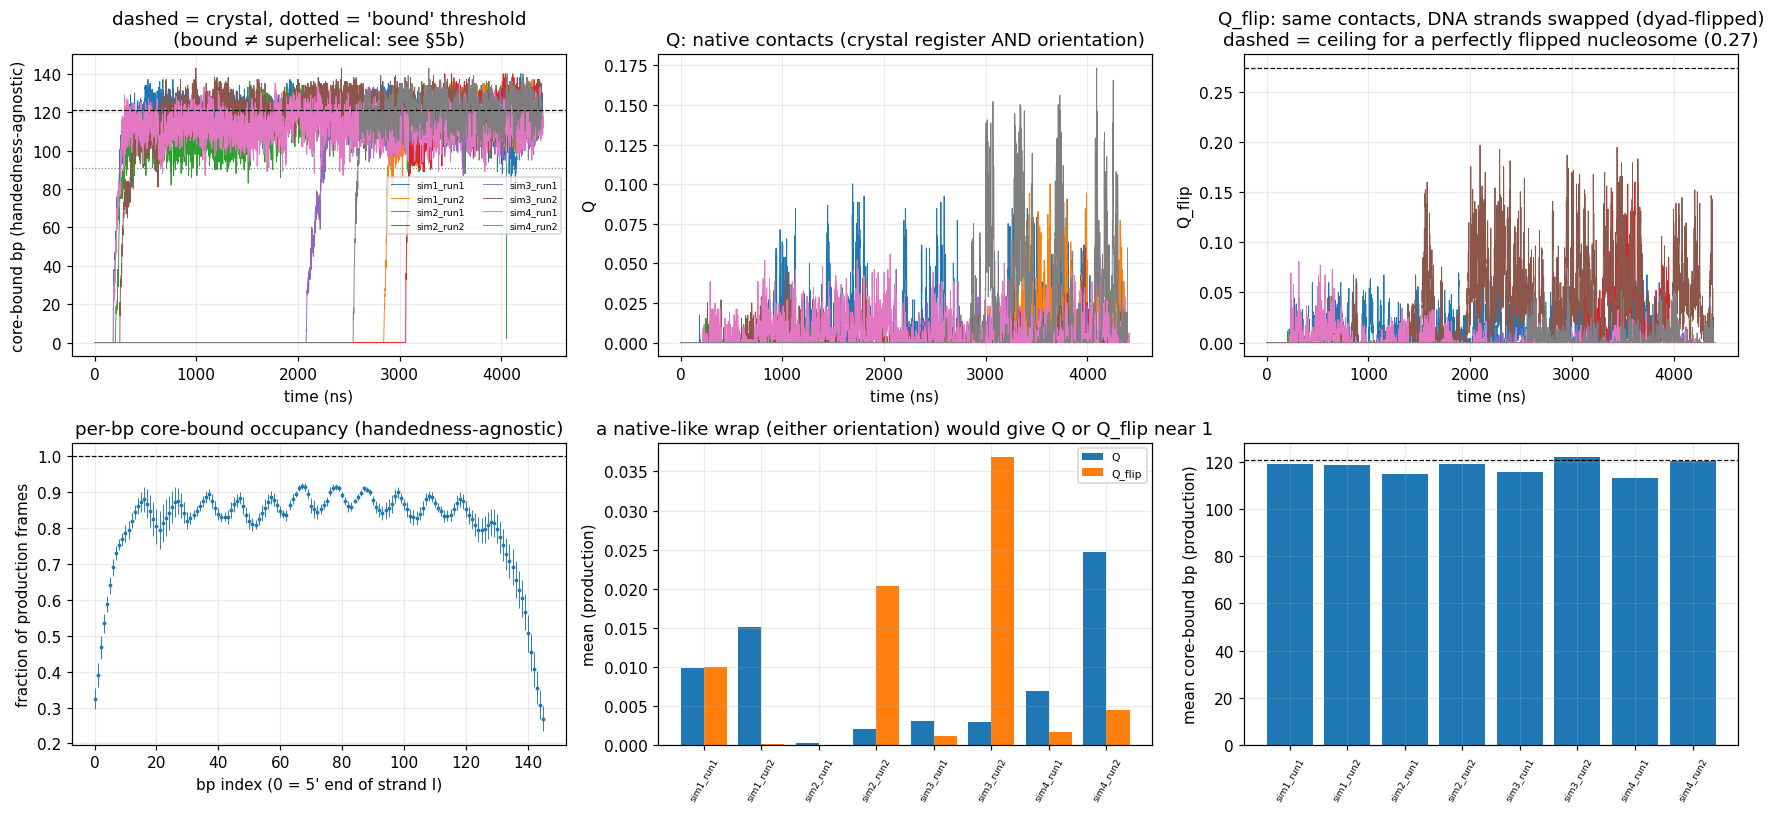

In [26]:
if ANALYSIS_COND and ANALYSIS_COND not in RES: print(f"ANALYSIS_COND={ANALYSIS_COND!r} not available (groups are created in §5b); using the first condition")
cond = ANALYSIS_COND if ANALYSIS_COND in RES else list(RES)[0]; Lw = REF["L"]; cr = CRYS[cond]
print(f"analysing: {cond}  (replicas: {list(RES[cond])})")
xl = f"time ({TIME_UNIT})" if FRAMES_TO_TIME else "frame"
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
for rep in RES[cond]:
    ax[0, 0].plot(tax(cond, rep, "n_close"), RES[cond][rep]["n_close"], lw=.6, label=rep)
    ax[0, 1].plot(tax(cond, rep, "Q"), RES[cond][rep]["Q"], lw=.6)
    ax[0, 2].plot(tax(cond, rep, "Q_flip"), RES[cond][rep]["Q_flip"], lw=.6)
ax[0, 0].axhline(cr["n_close"], c="k", ls="--", lw=.8); ax[0, 0].axhline(WRAP_FRAC_MIN * cr["n_close"], c="gray", ls=":", lw=.8)
ax[0, 0].set(xlabel=xl, ylabel="core-bound bp (handedness-agnostic)", title="dashed = crystal, dotted = 'bound' threshold\n(bound ≠ superhelical: see §5b)"); ax[0, 0].legend(fontsize=6, ncol=2)
ax[0, 1].set(xlabel=xl, ylabel="Q", title="Q: native contacts (crystal register AND orientation)")
ax[0, 2].axhline(cr["Q_flip_ref"], c="k", ls="--", lw=.8)
ax[0, 2].set(xlabel=xl, ylabel="Q_flip", title=f"Q_flip: same contacts, DNA strands swapped (dyad-flipped)\ndashed = ceiling for a perfectly flipped nucleosome ({cr['Q_flip_ref']:.2f})")
m, e = mean_sem(np.array([pmean(cond, r, "bp_close") for r in RES[cond]]))
ax[1, 0].errorbar(range(Lw), m, e, fmt=".", ms=3, lw=.6); ax[1, 0].axhline(1, c="k", ls="--", lw=.8)
ax[1, 0].set(xlabel="bp index (0 = 5' end of strand I)", ylabel="fraction of production frames", title="per-bp core-bound occupancy (handedness-agnostic)")
reps = list(RES[cond]); x = np.arange(len(reps))
ax[1, 1].bar(x - .2, [np.nanmean(prod(cond, r, "Q")) for r in reps], .4, label="Q"); ax[1, 1].bar(x + .2, [np.nanmean(prod(cond, r, "Q_flip")) for r in reps], .4, label="Q_flip")
ax[1, 1].set_xticks(x); ax[1, 1].set_xticklabels(reps, rotation=60, fontsize=6); ax[1, 1].set(ylabel="mean (production)", title="a native-like wrap (either orientation) would give Q or Q_flip near 1"); ax[1, 1].legend(fontsize=7)
ax[1, 2].bar(x, [np.nanmean(prod(cond, r, "n_close")) for r in reps]); ax[1, 2].axhline(cr["n_close"], c="k", ls="--", lw=.8)
ax[1, 2].set_xticks(x); ax[1, 2].set_xticklabels(reps, rotation=60, fontsize=6); ax[1, 2].set(ylabel="mean core-bound bp (production)")
plt.tight_layout()
print("per-replica means (production window):")
print(pd.DataFrame({r: dict(n_close=np.mean(prod(cond, r, "n_close")), u5c=np.mean(prod(cond, r, "u5c")), u3c=np.mean(prod(cond, r, "u3c")),
                            n_wrap_c=np.mean(prod(cond, r, "n_wrap_c")), Q=np.mean(prod(cond, r, "Q")), Q_flip=np.mean(prod(cond, r, "Q_flip")),
                            Q_max=np.max(np.maximum(prod(cond, r, "Q"), prod(cond, r, "Q_flip"))), n_native_bp=np.mean(prod(cond, r, "n_nat_bp")),
                            dna_rg=np.mean(prod(cond, r, "dna_rg"))) for r in RES[cond]}).T.infer_objects().round(3))
print(f"crystal: Q = 1 | Q_flip ceiling = {cr['Q_flip_ref']:.2f} | n_close={cr['n_close']} u5c={cr['u5c']} u3c={cr['u3c']} n_wrap_c={cr['n_wrap_c']} | DNA Rg of a wrapped nucleosome ≈ 44-45 Å")
print("n_close counts bp within R_CLOSE of the core: it does NOT require an ordered superhelix (DNA lying disordered on the positive core scores the same).\n"
      "The old 'wrapped bp (native-contact span)' was removed: it is the distance between the first and last natively bound bp, so two chance contacts\n"
      "far apart give a large value even when Q ~ 0; use n_native_bp (a count) instead.")

In [27]:
# How large are Q and Q_flip for an IDEAL native / dyad-flipped nucleosome that fluctuates like yours? (so that "Q = 0.17" can be judged)
rng_c = np.random.default_rng(0); Sx = STATIC[cond]
sig_core = float(np.mean([np.mean(prod(cond, r, "core_rmsd")) for r in RES[cond]])) / np.sqrt(3)     # per-coordinate sigma from the observed core RMSD
def _ideal(xyz, sd, sc, n=30):
    out = []
    for _ in range(n):
        d = xyz + rng_c.normal(0, sd, xyz.shape); c = Sx["core_ref_xyz"] + rng_c.normal(0, sc, Sx["core_ref_xyz"].shape)
        out.append(((np.linalg.norm(d[Sx["c_dj"]] - c[Sx["c_ci"]], axis=1) < GAMMA * Sx["c_d0"]).mean(),
                    (np.linalg.norm(d[Sx["c_dj_f"]] - c[Sx["c_ci_f"]], axis=1) < GAMMA * Sx["c_d0_f"]).mean()))
    return np.mean(out, 0)
cal = pd.DataFrame({f"DNA σ={sd:.0f} Å": {"ideal native: Q": _ideal(Sx["dna_xyz_cry"], sd, sig_core)[0], "ideal flipped: Q_flip": _ideal(Sx["dna_xyz_flip"], sd, sig_core)[1]}
                    for sd in (0, 1, 2, 3)})
print(f"Expected Q / Q_flip of an IDEAL nucleosome with independent Gaussian bead noise (core σ = {sig_core:.1f} Å per coordinate, from your core RMSD; DNA σ as given).")
print("Crude (independent noise, no correlation) but it shows the scale: contacts count only within GAMMA*d0, so Q never reaches 1 for a fluctuating state.")
print(cal.round(2).to_string())
q_id, qf_id = _ideal(Sx["dna_xyz_cry"], 2.0, sig_core)[0], _ideal(Sx["dna_xyz_flip"], 2.0, sig_core)[1]
rows = {}
for r in RES[cond]:
    q, qf = prod(cond, r, "Q"), prod(cond, r, "Q_flip")
    rows[r] = {"% frames Q>=0.10": 100 * (q >= .10).mean(), "% frames Q_flip>=0.10": 100 * (qf >= .10).mean(),
               f"% Q>={q_id/2:.2f} (half of ideal)": 100 * (q >= q_id / 2).mean(), f"% Q_flip>={qf_id/2:.2f} (half of ideal)": 100 * (qf >= qf_id / 2).mean(),
               "max Q": q.max(), "max Q_flip": qf.max()}
print("\nper replica (production window): share of frames in a native-like / flipped-native-like register (thresholds relative to the DNA σ = 2 Å ideal):")
print(pd.DataFrame(rows).T.infer_objects().round(2).to_string())

Expected Q / Q_flip of an IDEAL nucleosome with independent Gaussian bead noise (core σ = 1.7 Å per coordinate, from your core RMSD; DNA σ as given).
Crude (independent noise, no correlation) but it shows the scale: contacts count only within GAMMA*d0, so Q never reaches 1 for a fluctuating state.
                       DNA σ=0 Å  DNA σ=1 Å  DNA σ=2 Å  DNA σ=3 Å
ideal native: Q             0.68       0.64       0.54       0.44
ideal flipped: Q_flip       0.27       0.27       0.26       0.24

per replica (production window): share of frames in a native-like / flipped-native-like register (thresholds relative to the DNA σ = 2 Å ideal):
           % frames Q>=0.10  % frames Q_flip>=0.10  % Q>=0.27 (half of ideal)  % Q_flip>=0.12 (half of ideal)  max Q  max Q_flip
sim1_run1              0.06                   0.00                        0.0                            0.00   0.10        0.09
sim1_run2              0.07                   0.00                        0.0                      

**Experimental comparison — wrapping / breathing**

| Simulation quantity | Experimental counterpart | Caveat |
|---|---|---|
| Reference geometry: on the 2CV5 CG structure this notebook gets n_wrap(native) = 144, n_close = 121, wrapping angle ≈ 646° (1.80 turns) — see the printed `CRYSTAL reference` line | crystal structures: Luger *et al.* 1997 *Nature* 389:251; Davey *et al.* 2002 *JMB* 319:1097; Tsunaka *et al.* 2005 *NAR* 33:3424 (= 2CV5, your source) | The crystal is the target, not an independent measurement of solution behaviour. Use the printed crystal values as the reference; the often-quoted "1.65 turns" is counted differently from the bp-centre angle computed here. |
| Per-bp core-bound occupancy (high in the centre, lower toward the ends) | Experimental accessibility gradient along nucleosomal DNA (restriction-enzyme site exposure): Polach & Widom 1995 *JMB* 254:130; Anderson & Widom 2000 *JMB* 296:979; Li & Widom 2004 *NSMB* 11:763 | These papers measure site exposure/accessibility, not contact occupancy. Compare only the qualitative end-to-dyad gradient, not absolute values. |
| Wrapped bp, unwrapped length at each end (`u5c`, `u3c`) | Spontaneous end unwrapping (smFRET / restriction accessibility): Li *et al.* 2005 *NSMB* 12:46; Koopmans *et al.* 2007; Gansen *et al.* 2009 *PNAS* | Only ~10–20 bp at each end unwrap appreciably in the experiments; CG time scales are not real time. `u5c/u3c` count from the first/last core-bound bp (contact-free stretches inside the wrapped region do not count as unwrapped). |

*Representative experimental references for nucleosome structure, accessibility, and DNA breathing. Exact correspondence between experimental observables and simulation metrics should be interpreted cautiously.*

## 5b. Handedness of the wrapped DNA (all replicas)
Per analysed frame, the bp-centre path between the first and last core-bound bp is fitted with a helix **about its own axis** (PCA axis + circle fit, independent of any reference frame): signed pitch > 0 = right-handed, < 0 = left-handed; frames need ≥ `HAND_MIN_BP` bp and a span ≥ `HAND_MIN_SPAN`° to be classified, and |pitch| < `HAND_MIN_PITCH` is "ambiguous". The crystal is classified with the same function and must come out **LEFT** (printed below) — if it does not, the classifier is broken. The helix fit must also be good (|corr(φ,z)| ≥ `HAND_MIN_CORR`), otherwise the frame counts as *bound, not superhelical*. A secondary, independent test compares the bp path with the crystal path after rigid superposition with and without allowing a mirror image (`hand_shape`, reported as *shape agrees*); it only gives a verdict when the DNA path resembles the crystal path to within `SHAPE_MAX`. **Replica verdict** = the sequence of stable handedness segments (each ≥ `HAND_MIN_DWELL` classified frames; ambiguous frames are skipped; short blips are discarded): `RIGHT`, `LEFT`, or e.g. `R→L` if the handedness changes during the run. Percentages are shares of production-window frames in each state; the state timeline shows when each replica wraps, when it is bound without an ordered superhelix, and when it switches. If replicas differ, groups such as `baseline[LEFT]` are created automatically (`ANALYSIS_COND`).

[baseline] crystal 2CV5, same classifier: signed pitch -21.5 Å/turn, span 647°, corr -0.88 -> LEFT-handed (sign convention: > 0 right-handed; the crystal must come out LEFT)

[baseline] verdict = sequence of stable handedness segments over the WHOLE trajectory (>= 50 classified frames each);
      percentages = share of production-window frames in each state:
          verdict  switches final  pct_not_bound  pct_bound_disordered  pct_ambiguous  pct_right  pct_left  classified_frames  window_frames  wrapped_at_frame
sim1_run1     R→L         1     L            0.5                   7.6            0.0       84.1       7.9               3242           3525              2460
sim1_run2   RIGHT         0     R            0.3                  86.9            0.0       12.8       0.0                192           1505             28890
sim2_run1   RIGHT         0     R            0.2                  29.3            0.0       70.4       0.0               2283           3241              2980
si

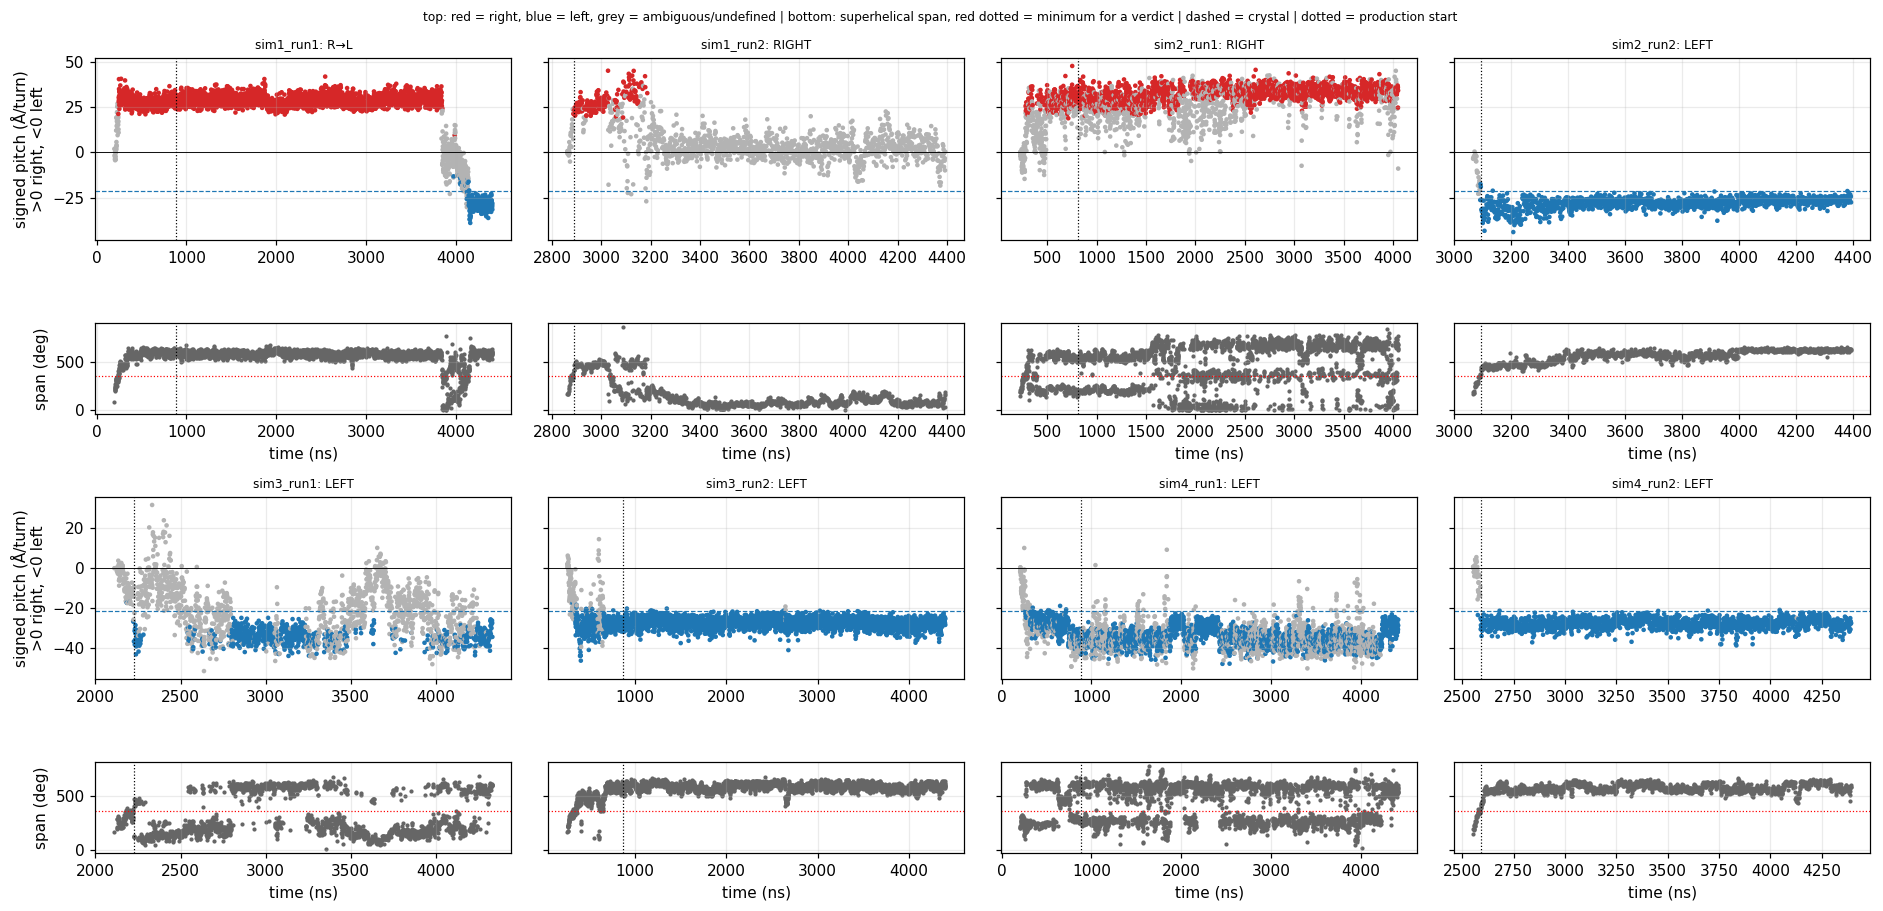

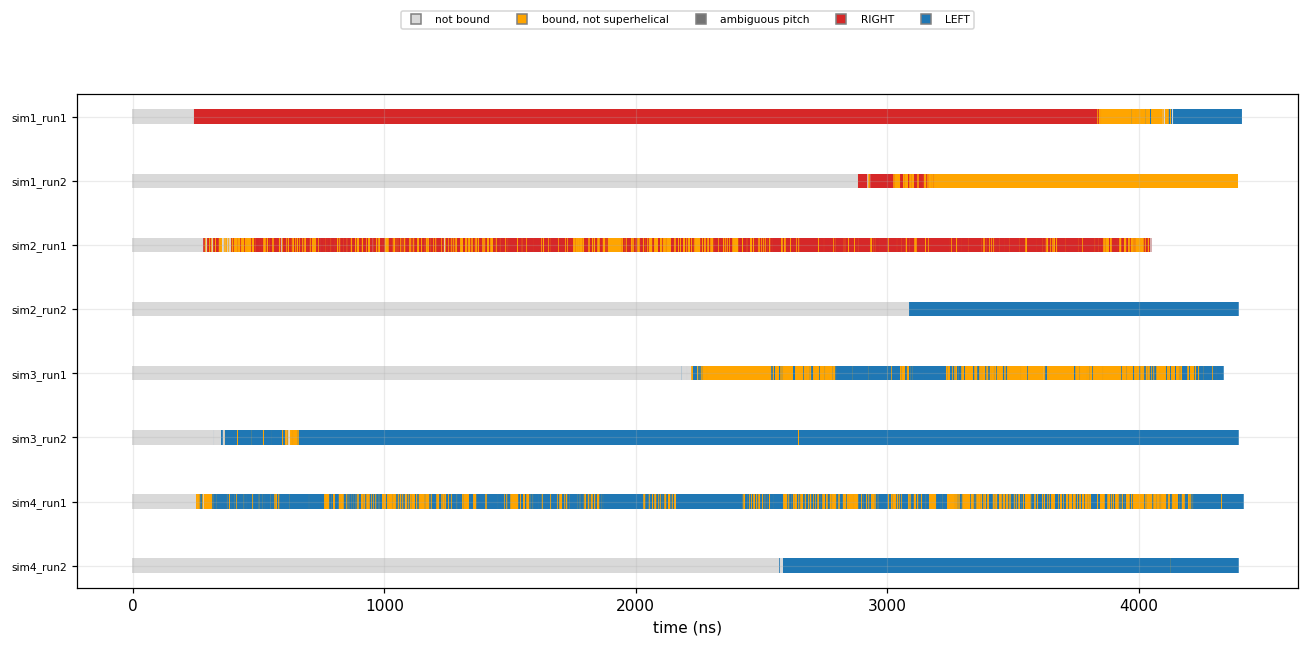

In [28]:
STATE_NAMES  = ["not bound", "bound, not superhelical", "ambiguous pitch", "RIGHT", "LEFT"]
STATE_COLORS = ["0.85", "orange", "0.45", "tab:red", "tab:blue"]

def state_codes(cond, rep):
    """per analysed frame: 0 not bound | 1 core-bound but no ordered superhelix (span<360°, <40 bp or poor helix fit) | 2 |pitch| too small | 3 RIGHT | 4 LEFT"""
    need = WRAP_FRAC_MIN * CRYS[cond]["n_close"]; nc, h = RES[cond][rep]["n_close"], RES[cond][rep]["hand"]
    s = np.zeros(len(nc), int); s[nc >= need] = 1; s[(nc >= need) & (h == 0)] = 2; s[h == 1] = 3; s[h == -1] = 4
    return s

def hand_segments(h, fr, min_dwell=None):
    """Runs of consistent classified handedness (+1/-1). Ambiguous/undefined frames are skipped; runs with fewer than min_dwell
    classified frames are discarded (noise); neighbouring runs of the same sign left after that are merged.
    Returns [(first_frame, last_frame, +1/-1, n_classified)]."""
    min_dwell = HAND_MIN_DWELL if min_dwell is None else min_dwell
    ok = (h == 1) | (h == -1); hs, fs = h[ok], fr[ok]
    if len(hs) == 0: return []
    cut = np.where(np.diff(hs) != 0)[0] + 1; a, b = np.r_[0, cut], np.r_[cut, len(hs)]
    keep = [(int(fs[i]), int(fs[j - 1]), int(hs[i]), int(j - i)) for i, j in zip(a, b) if j - i >= min_dwell]
    merged = []
    for s_ in keep:
        if merged and merged[-1][2] == s_[2]: merged[-1] = (merged[-1][0], s_[1], s_[2], merged[-1][3] + s_[3])
        else: merged.append(s_)
    return merged

def handedness_table(cond):
    rows = {}
    for rep in RES[cond]:
        fr = FRM[cond][rep]["n_close"]; m = fr >= PROD_START[(cond, rep)][0]
        st = state_codes(cond, rep); h, hs = RES[cond][rep]["hand"], RES[cond][rep]["hand_shape"]
        pct = lambda k: 100 * (st[m] == k).mean() if m.any() else np.nan
        segs = hand_segments(h, fr); pat = "→".join("R" if s_[2] == 1 else "L" for s_ in segs)
        verdict = {"": "no stable superhelix", "R": "RIGHT", "L": "LEFT"}.get(pat, pat)
        both = m & ((h == 1) | (h == -1)) & ((hs == 1) | (hs == -1))
        rows[rep] = dict(verdict=verdict, switches=max(len(segs) - 1, 0), final=("-" if not segs else ("R" if segs[-1][2] == 1 else "L")),
                         segments=" | ".join(f"{'R' if s_[2]==1 else 'L'} {s_[0]}–{s_[1]}" for s_ in segs),
                         pct_not_bound=pct(0), pct_bound_disordered=pct(1), pct_ambiguous=pct(2), pct_right=pct(3), pct_left=pct(4),
                         classified_frames=int((m & ((h == 1) | (h == -1))).sum()), window_frames=int(m.sum()),
                         shape_agrees_pct=100 * (h[both] == hs[both]).mean() if both.any() else np.nan,
                         Q=np.nanmean(RES[cond][rep]["Q"][m]) if m.any() else np.nan, Q_flip=np.nanmean(RES[cond][rep]["Q_flip"][m]) if m.any() else np.nan,
                         wrapped_at_frame=PROD_START[(cond, rep)][1])
    return pd.DataFrame(rows).T.infer_objects()      # .T makes every column object dtype: restore float/int so .round() and plotting work

GROUPS = {}     # group name -> parent condition
def split_by_verdict(cd):
    """If the replicas of condition `cd` have different verdicts, create pseudo-conditions '<cd>[RIGHT]', '<cd>[LEFT]', '<cd>[R→L]' ...
    (sharing the same data) so that §5–§10 can be run separately per group: set ANALYSIS_COND = '<cd>[LEFT]' and re-run from §5."""
    T = handedness_table(cd); verd = {v: [r for r in RES[cd] if T.loc[r, "verdict"] == v] for v in T["verdict"].unique() if v != "no stable superhelix"}
    if len(verd) < 2: print(f"[{cd}] all replicas with a stable superhelix agree ({', '.join(verd) or 'none'}): no split needed"); return
    for v, reps in verd.items():
        name = f"{cd}[{v}]"
        for D in (RES, FRM, INFO): D[name] = {r: D[cd][r] for r in reps}
        STATIC[name], CRYS[name], GROUPS[name] = STATIC[cd], CRYS[cd], cd
        for r in reps: PROD_START[(name, r)] = PROD_START[(cd, r)]
        print(f"[{cd}] created group {name!r}: {reps}")
    print("-> set ANALYSIS_COND to one of these and re-run §5 and §6–§10 to analyse that group on its own")

for cd in [c for c in RES if "[" not in c]:
    cr = CRYS[cd]
    print(f"[{cd}] crystal 2CV5, same classifier: signed pitch {cr['hand_pitch']:+.1f} Å/turn, span {cr['hand_span']:.0f}°, corr {cr['hand_corr']:+.2f} -> "
          f"{'RIGHT' if cr['hand_pitch'] > 0 else 'LEFT'}-handed (sign convention: > 0 right-handed; the crystal must come out LEFT)")
    T = handedness_table(cd)
    pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 80)
    print(f"\n[{cd}] verdict = sequence of stable handedness segments over the WHOLE trajectory (>= {HAND_MIN_DWELL} classified frames each);\n"
          f"      percentages = share of production-window frames in each state:")
    print(T[["verdict", "switches", "final", "pct_not_bound", "pct_bound_disordered", "pct_ambiguous", "pct_right", "pct_left", "classified_frames", "window_frames", "wrapped_at_frame"]].round(1).to_string())
    print("\nsegments (first–last analysed frame):"); print(T["segments"].to_string())
    print("\nsecondary mirror-image test agrees with the helix-fit handedness in (% of classified frames):", pd.to_numeric(T["shape_agrees_pct"], errors="coerce").round(1).to_dict())
    print("verdict counts:", T["verdict"].value_counts().to_dict())
    reps = list(RES[cd]); ncol = min(4, len(reps)); nrow = int(np.ceil(len(reps) / ncol))
    fig, axs = plt.subplots(2 * nrow, ncol, figsize=(4.3 * ncol, 4.2 * nrow), squeeze=False, sharey="row", gridspec_kw=dict(height_ratios=[2, 1] * nrow))
    for k, rep in enumerate(reps):
        a, a2 = axs[2 * (k // ncol), k % ncol], axs[2 * (k // ncol) + 1, k % ncol]
        p, h = RES[cd][rep]["hand_pitch"], RES[cd][rep]["hand"]; t = tax(cd, rep, "hand_pitch")
        a.scatter(t, p, c=np.where(h == 1, "tab:red", np.where(h == -1, "tab:blue", "0.7")), s=4)
        a.axhline(0, c="k", lw=.6); a.axhline(cr["hand_pitch"], c="tab:blue", ls="--", lw=.8)
        a.set_title(f"{rep}: {T.loc[rep, 'verdict']}", fontsize=8)
        a2.scatter(t, RES[cd][rep]["hand_span"], c="0.4", s=3); a2.axhline(HAND_MIN_SPAN, c="r", ls=":", lw=.8); a2.set(xlabel=xl)
        for ax_ in (a, a2): ax_.axvline(PROD_START[(cd, rep)][0] * (FRAMES_TO_TIME or 1), c="k", ls=":", lw=.8)
    for k in range(len(reps), nrow * ncol): axs[2 * (k // ncol), k % ncol].axis("off"); axs[2 * (k // ncol) + 1, k % ncol].axis("off")
    for r_ in range(nrow): axs[2 * r_, 0].set_ylabel("signed pitch (Å/turn)\n>0 right, <0 left"); axs[2 * r_ + 1, 0].set_ylabel("span (deg)")
    fig.suptitle("top: red = right, blue = left, grey = ambiguous/undefined | bottom: superhelical span, red dotted = minimum for a verdict | dashed = crystal | dotted = production start", fontsize=8)
    plt.tight_layout()
    # state timeline of every replica
    fig2, a3 = plt.subplots(figsize=(12, 0.55 * len(reps) + 1.6))
    for k, rep in enumerate(reps):
        st = state_codes(cd, rep); t = tax(cd, rep, "n_close")
        a3.scatter(t, np.full(len(t), k), c=[STATE_COLORS[i] for i in st], marker="|", s=90, linewidths=1.0)
    a3.set_yticks(range(len(reps))); a3.set_yticklabels(reps, fontsize=7); a3.invert_yaxis(); a3.set(xlabel=xl)
    a3.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=c, mec="0.5", label=n) for c, n in zip(STATE_COLORS, STATE_NAMES)], fontsize=7, ncol=5, loc="upper center", bbox_to_anchor=(.5, 1.18))
    plt.tight_layout()
    split_by_verdict(cd)

**Experimental comparison — handedness**

* Every nucleosome crystal structure (Luger 1997, Davey 2002, Tsunaka 2005) has **left-handed** DNA superhelix. A right-handed wrapped state is therefore *not* comparable to the experimental nucleosome; report it as a property of the model (e.g. wrapping driven by electrostatics without any term that selects the crystal handedness), not as a nucleosome observable.
* If replicas differ (RIGHT in some, LEFT in others) do not pool them in §6–§10 — analyse the groups separately. A replica whose verdict is `R→L` changes handedness during the run: look at the segment table and the structures around the switch before assigning it to a group (the groups are made from the verdict string, so `R→L` forms its own group).
* `Q` (native) is non-zero only for a LEFT wrap in the crystal register and orientation; `Q_flip` is non-zero for a LEFT wrap in the dyad-flipped orientation. If both are ≈ 0 for a LEFT replica the DNA is left-handed but not in a native-like register (e.g. shifted along the superhelix).
* "Bound, not superhelical" frames have DNA on the core (`n_close`) without an ordered superhelix (span < 360°, < 40 bp or a poor helix fit); they are not classified and must not be counted as wrapped nucleosomes.
* The own-axis pitch is biased low by ~10 % for a non-integer number of turns; only the **sign** is used for classification.

## 6. Site exposure (the direct analogue of restriction-enzyme accessibility) and F(N_wrap)
A site of length *w* bp, starting *s* bp from a DNA end, is "exposed" when the unwrapped length at that end is ≥ *s + w*. Then K(s) = P_exposed / (1 − P_exposed) and ΔG(s) = −kT ln K(s).

crystal reference on the same definition: u5c=0, u3c=2, n_wrap_c=144


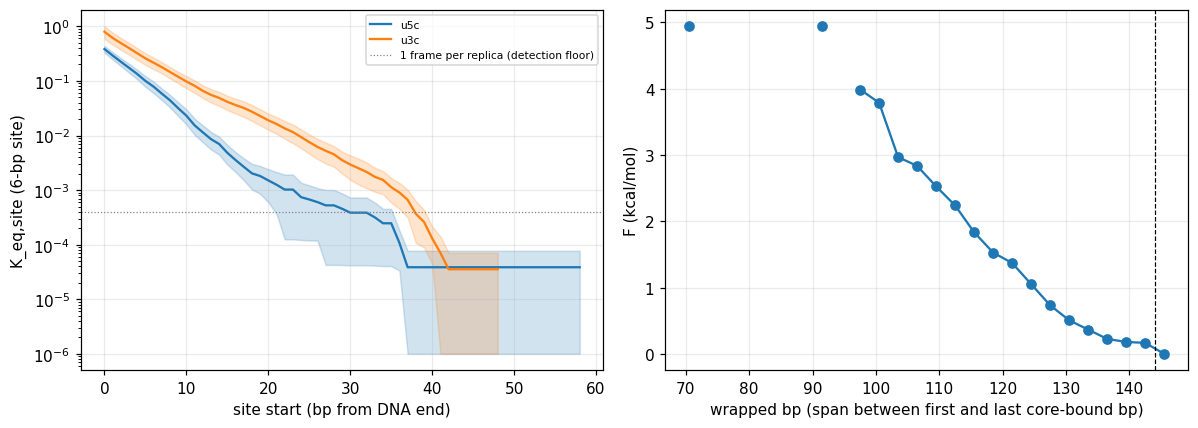

In [29]:
def site_exposure(cond, w=6, smax=60, ends=("u5c", "u3c")):
    """uses the handedness-agnostic unwrapped lengths u5c/u3c (use ends=("u5","u3") only for crystal-register wrapping)"""
    s_ = np.arange(0, smax); out = {}
    for end in ends:
        per_rep = []
        for r in RES[cond]:
            u = prod(cond, r, end); per_rep.append(np.array([(u >= s + w).mean() if len(u) else np.nan for s in s_]))
        out[end] = np.array(per_rep)
    return s_, out

s_, SE = site_exposure(cond)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for end, c in (("u5c", "C0"), ("u3c", "C1")):
    p = SE[end]; K = p / (1 - p + 1e-12); m, e = mean_sem(K)
    ok = np.isfinite(m) & (m > 0)
    ax[0].semilogy(s_[ok], m[ok], c=c, label=end); ax[0].fill_between(s_[ok], np.maximum(m - e, 1e-6)[ok], (m + e)[ok], color=c, alpha=.2)
_nfr = np.mean([len(prod(cond, r, "u5c")) for r in RES[cond]])
ax[0].axhline(1.0 / max(_nfr, 1), c="gray", ls=":", lw=.8, label="1 frame per replica (detection floor)")
ax[0].set(xlabel="site start (bp from DNA end)", ylabel="K_eq,site (6-bp site)"); ax[0].legend(fontsize=7)
N = pooled(cond, "n_wrap_c")
if len(N):
    hist, edges = np.histogram(N, bins=np.arange(0, REF["L"] + 4, 3), density=True)
    F = -KT * np.log(np.where(hist > 0, hist, np.nan)); ax[1].plot(0.5 * (edges[1:] + edges[:-1]), F - np.nanmin(F), "o-")
ax[1].axvline(CRYS[cond]["n_wrap_c"], c="k", ls="--", lw=.8)
ax[1].set(xlabel="wrapped bp (span between first and last core-bound bp)", ylabel="F (kcal/mol)"); plt.tight_layout()
print(f"crystal reference on the same definition: u5c={CRYS[cond]['u5c']}, u3c={CRYS[cond]['u3c']}, n_wrap_c={CRYS[cond]['n_wrap_c']}")

**Experimental comparison — site exposure and F(N_wrap)**

* K(s) vs s is the quantity measured by Polach & Widom (1995), Anderson & Widom (2000) and Li & Widom (2004) with restriction enzymes at many positions: K falls steeply (orders of magnitude) from the DNA ends toward the dyad. Look up the table values in those papers and overlay them (ΔG = −kT ln K). Expect agreement in trend; the absolute magnitudes of a CG force field without tails/sequence-specific terms will differ.
* Force spectroscopy gives complementary information on the energetics of unwrapping (Brower-Toland *et al.* 2002 *PNAS* 99:1960; Mihardja *et al.* 2006 *PNAS* 103:15871; Hall *et al.* 2009 *NSMB* 16:124; Ngo *et al.* 2015 *Cell* 160:1135). These need a *pulling* simulation to compare quantitatively; F(N_wrap) from equilibrium runs is only a qualitative cross-check (barrier near the entry/exit region, multi-stage unwrapping).
* Caveat: a 4-day CG run may sample few deep-unwrapping events, so K for large s may be 0 (not measurable) — report which positions are statistically resolved.

## 7. Superhelix geometry and end-to-end distances

CRYSTAL (2CV5 bp centres, bound range): wrapping angle = 647° (1.80 turns), radius = 41.9 Å, |pitch| = 21.3 Å (PCA-axis pitch is biased low by ~10 %: compare with this crystal value only, not with literature)
core rmsd to crystal (Å): {'sim1_run1': 2.96, 'sim1_run2': 2.92, 'sim2_run1': 3.22, 'sim2_run2': 3.02, 'sim3_run1': 3.02, 'sim3_run2': 2.9, 'sim4_run1': 3.0, 'sim4_run2': 2.87}
FRET-pair bp distances (Å), mean ± sd (crystal in brackets): [((0, 145), np.float64(94.5), np.float64(25.9), '[63.4]'), ((10, 135), np.float64(83.1), np.float64(14.2), '[87.6]')]


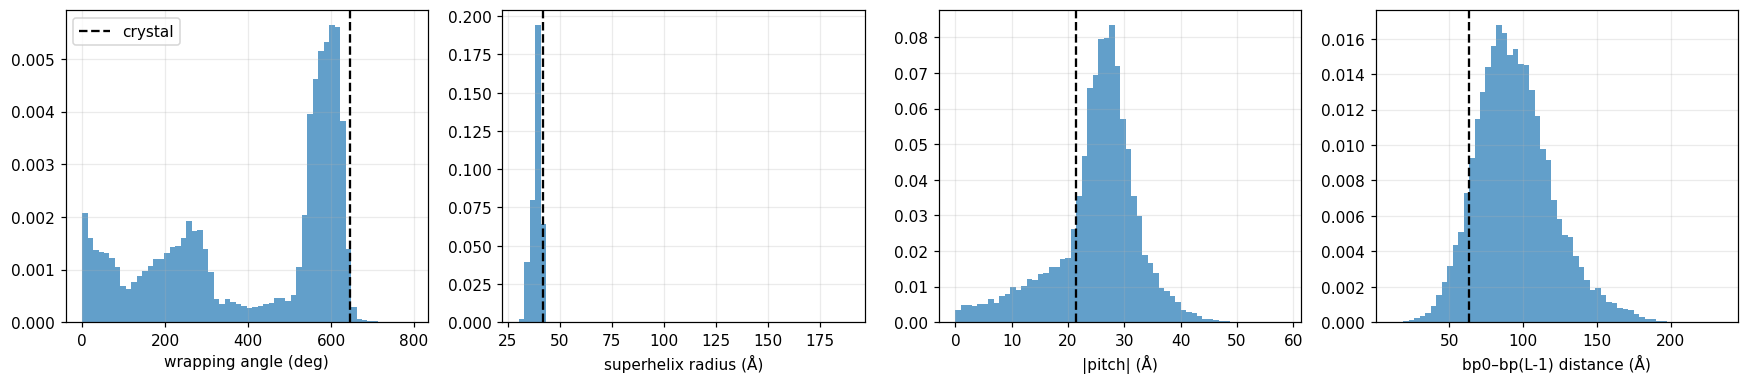

In [30]:
cr = CRYS[cond]
print(f"CRYSTAL (2CV5 bp centres, bound range): wrapping angle = {cr['wrap_angle']:.0f}° ({cr['wrap_angle']/360:.2f} turns), radius = {cr['radius']:.1f} Å, "
      f"|pitch| = {cr['pitch']:.1f} Å (PCA-axis pitch is biased low by ~10 %: compare with this crystal value only, not with literature)")
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, nm, ref_v, lab in zip(ax, ["wrap_angle", "radius", "pitch", "end_dist"], [cr["wrap_angle"], cr["radius"], cr["pitch"], cr["end_dist"]],
                             ["wrapping angle (deg)", "superhelix radius (Å)", "|pitch| (Å)", "bp0–bp(L-1) distance (Å)"]):
    x = pooled(cond, nm); x = x[np.isfinite(x)]
    if len(x): a.hist(x, bins=60, density=True, alpha=.7)
    a.axvline(ref_v, c="k", ls="--", label="crystal"); a.set(xlabel=lab)
ax[0].legend(); plt.tight_layout()
print("core rmsd to crystal (Å):", {r: round(float(np.mean(prod(cond, r, 'core_rmsd'))), 2) for r in RES[cond]})
fd = pooled(cond, "fret_dist")
print("FRET-pair bp distances (Å), mean ± sd (crystal in brackets):",
      [(FRET_PAIRS[k], round(fd[:, k].mean(), 1), round(fd[:, k].std(), 1), f"[{cr['fret_dist'][k]:.1f}]") for k in range(len(FRET_PAIRS))])

**Experimental comparison — geometry / FRET**

* Compare radius and pitch with the **crystal values printed above** (computed from your 2CV5 CG model with the same function). Literature numbers for the DNA superhelix (Luger 1997: pitch ≈ 24 Å, radius ≈ 42 Å — verify in the paper) differ from the PCA-axis values because that pitch is biased low by ~10 %.
* The geometry is evaluated on the handedness-agnostic bound range and in the crystal frame; for a right-handed wrapped state `radius`, `wrap_angle` and `end_dist` remain meaningful, but the superhelix is the mirror image of the crystal one.
* End-to-end / FRET-pair distances: smFRET on labelled nucleosomes (Li & Widom 2005; Koopmans 2007; Gansen 2009 — pick the paper whose dye positions you want to mimic and set `FRET_PAIRS`). Convert distance to efficiency with the dye's Förster radius **R0** (E = 1/(1+(r/R0)^6)); dye linkers add several Å of uncertainty, so use ensembles/thresholds (open vs closed), not single numbers.

## 8. Ion atmosphere: excess ions, charge neutralisation, Mg²⁺ preference
Γ_i(r) = N_i(<r) − ρ_i,bulk · V(<r), with *r* = distance to the nearest bead of the complex and ρ_bulk measured beyond R_MAX (so box-size depletion is accounted for). Shell volumes V(<r) are computed **per frame**. Model charges: phosphate −0.6 e, K/R +1, D/E −1, His +1 (assumed); the box is neutral with these (checked in §2). For a neutral box Σ q·Γ → −Q_complex at large r automatically, so the ratio to the complex charge is a sanity check; the informative quantities are the *split* between species and the radial profile.

ion frames skipped (sampling cube does not fit into the box, i.e. extended DNA before wrapping): {'sim1_run1': 12, 'sim1_run2': 235, 'sim2_run1': 18, 'sim2_run2': 290, 'sim3_run1': 175, 'sim3_run2': 19, 'sim4_run1': 13, 'sim4_run2': 190}
bulk concentrations (M), measured beyond R_MAX: {'K': np.float64(0.0501), 'Cl': np.float64(0.066), 'Mg': np.float64(0.0079)}
Excess ions per nucleosome at r = 50.0 Å  (n = 8 replicas):
        mean   sem
K      3.97  0.46
Cl     4.17  0.64
Mg    13.08  0.18
Σ qΓ  25.98  0.16
model charges: DNA -174.0 e, histone +148.0 e, complex -26.0 e
atmosphere charge / |complex net charge|        = 1.00   (-> 1 for a neutral box at large r; a sanity check, not a result)
atmosphere charge / |DNA phosphate charge|      = 0.15   (compare with free-DNA / ion-counting numbers)
charge from cations: +30.1 e ; from anions: -4.2 e   (anion term > 0: Cl- depleted, < 0: Cl- ENRICHED near the complex)
note: a 1 % error in a bulk density shifts Γ(50 Å) by {'K': np.float64(1.3),

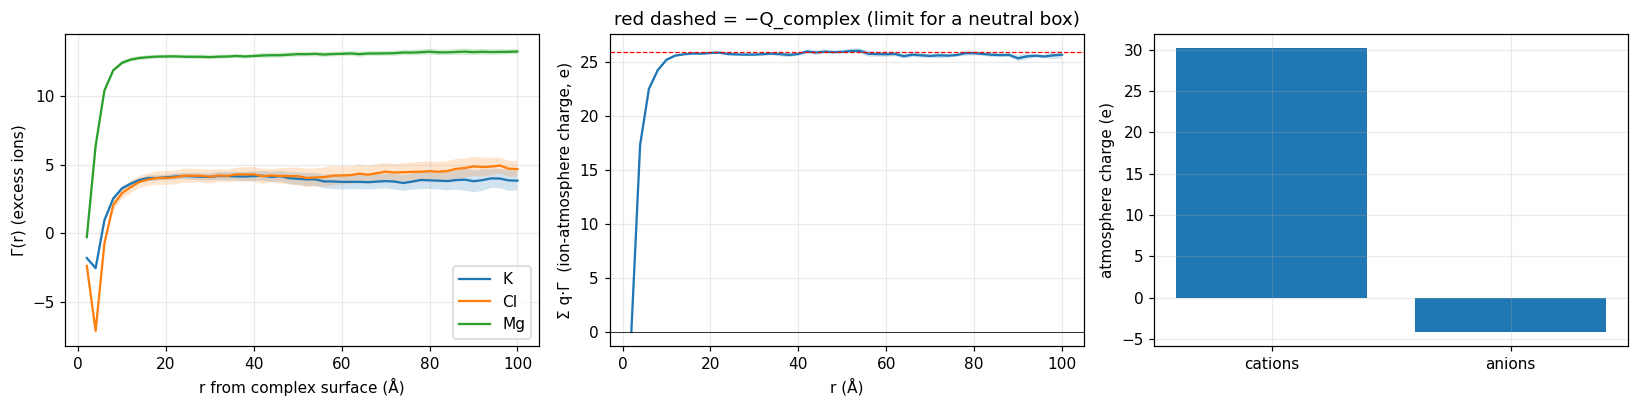

In [31]:
Sx = STATIC[cond]
IONS = [k for k in ION_RESNAMES if any(f"gam_{k}" in RES[cond][r] for r in RES[cond])]
_skipped = {r: INFO[cond][r]["ion_skipped"] for r in RES[cond]}
print("ion frames skipped (sampling cube does not fit into the box, i.e. extended DNA before wrapping):", _skipped)
reps_i = [r for r in RES[cond] if IONS and f"gam_{IONS[0]}" in RES[cond][r] and len(prod(cond, r, f"gam_{IONS[0]}")) > 0]
if not reps_i:
    print("no ion data in the production window (no box, or every ion frame skipped)")
else:
    rr = EDGES[1:]                       # upper edge of each shell (Å)
    G = {k: np.array([pmean(cond, r, f"gam_{k}") for r in reps_i]) for k in IONS}   # reps × bins
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for k in IONS:
        m, e = mean_sem(G[k]); ax[0].plot(rr, m, label=k); ax[0].fill_between(rr, m - e, m + e, alpha=.2)
    net = sum(ION_Q[k] * G[k] for k in IONS); m, e = mean_sem(net)
    ax[1].plot(rr, m); ax[1].fill_between(rr, m - e, m + e, alpha=.2); ax[1].axhline(0, c="k", lw=.5); ax[1].axhline(-Sx["Q_complex"], c="r", ls="--", lw=.8)
    ax[0].set(xlabel="r from complex surface (Å)", ylabel="Γ(r) (excess ions)"); ax[0].legend()
    ax[1].set(xlabel="r (Å)", ylabel="Σ q·Γ  (ion-atmosphere charge, e)", title="red dashed = −Q_complex (limit for a neutral box)")
    b = {k: np.nanmean([np.nanmean(prod(cond, r, f"bulk_M_{k}")) for r in reps_i]) for k in IONS}
    print("bulk concentrations (M), measured beyond R_MAX:", {k: round(v, 4) for k, v in b.items()})
    ip = int(np.argmin(abs(rr - R_PLATEAU))); sem = lambda x: x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
    tab = pd.DataFrame({k: dict(zip(["mean", "sem"], [G[k][:, ip].mean(), sem(G[k][:, ip])])) for k in IONS}).T
    tab.loc["Σ qΓ"] = [net[:, ip].mean(), sem(net[:, ip])]
    print(f"Excess ions per nucleosome at r = {R_PLATEAU} Å  (n = {len(reps_i)} replicas):\n", tab.round(2))
    nm = net[:, ip].mean()
    print(f"model charges: DNA {Sx['Q_dna']:+.1f} e, histone {Sx['Q_histone']:+.1f} e, complex {Sx['Q_complex']:+.1f} e")
    print(f"atmosphere charge / |complex net charge|        = {nm/abs(Sx['Q_complex']):.2f}   (-> 1 for a neutral box at large r; a sanity check, not a result)")
    print(f"atmosphere charge / |DNA phosphate charge|      = {nm/abs(Sx['Q_dna']):.2f}   (compare with free-DNA / ion-counting numbers)")
    # share of the compensation from cation gain vs anion loss (both are positive contributions to the atmosphere charge)
    cat = sum(ION_Q[k] * G[k][:, ip].mean() for k in IONS if ION_Q[k] > 0)
    an = sum(ION_Q[k] * G[k][:, ip].mean() for k in IONS if ION_Q[k] < 0)
    print(f"charge from cations: {cat:+.1f} e ; from anions: {an:+.1f} e   (anion term > 0: Cl- depleted, < 0: Cl- ENRICHED near the complex)")
    Vp = np.nanmean([pmean(cond, r, "vol")[ip] for r in reps_i])          # mean V(<R_PLATEAU), Å^3
    d1 = {k: round(0.01 * b[k] / 1660.539 * Vp, 1) for k in IONS}
    print(f"note: a 1 % error in a bulk density shifts Γ({R_PLATEAU:.0f} Å) by {d1} ions (ρ·V, V = {Vp:.2e} Å^3): "
          "K+/Cl- excesses of a few ions are not interpretable individually; the Mg2+ and net values are")
    ax[2].bar(["cations", "anions"], [cat, an]); ax[2].set_ylabel("atmosphere charge (e)"); plt.tight_layout()

**Experimental comparison — ion counting**

* Gebala, Johnson, Narlikar & Herschlag, *eLife* 2019;8:e44993 measured the ion atmosphere of nucleosomes by ion counting. Their conclusions you can test qualitatively: (i) the nucleosome keeps a strong negative electrostatic field although its net charge is roughly halved relative to free DNA; (ii) charge compensation comes mainly from **cation accumulation**, with anion exclusion contributing less; (iii) the nucleosome attracts the divalent cation (Mg²⁺) preferentially over monovalent ions. Get the measured excess-ion numbers and the salt conditions from the paper's figures/tables before overlaying — they used Na⁺/Mg²⁺ (not K⁺) and a specific nucleosome construct.
* Free-DNA benchmark for the same quantities: Bai, Greenfeld, Travers & Herschlag, *JACS* 2007, 129:14981 (ion counting on a short DNA duplex). Running the same analysis on a bare-DNA simulation gives the nucleosome/free-DNA comparison that Gebala et al. make.
* Caveat: the simulation uses a dielectric-scaled, implicit-water model with bare-charge point ions, so compare the *ordering and trends* (Mg²⁺ ≫ K⁺ per unit charge, cation-dominated neutralisation), and quote numbers with the plateau radius stated.
* Charges in this model: phosphate −0.6 e (TIS), so the DNA charge is −174 e, not −290 e; compare per-phosphate numbers with that in mind.

## 9. Local Mg²⁺ along the DNA vs. crystallographic metal sites

bulk Mg²⁺ = 7.9 mM
mean local [Mg²⁺] around phosphates (within 10 Å): 69 mM = 8.7x bulk
mean local [Mg²⁺] around base beads (within 8 Å): 76 mM = 9.6x bulk
spread along the DNA (std of the per-bp profile): phosphates 13 mM, base beads 14 mM  (includes statistical noise and the DNA ends; compare it with the error bars in the plot)
The CG DNA has no base atoms and no site-specific Mg²⁺ term: any enrichment here is electrostatic, uniform and non-specific by construction.


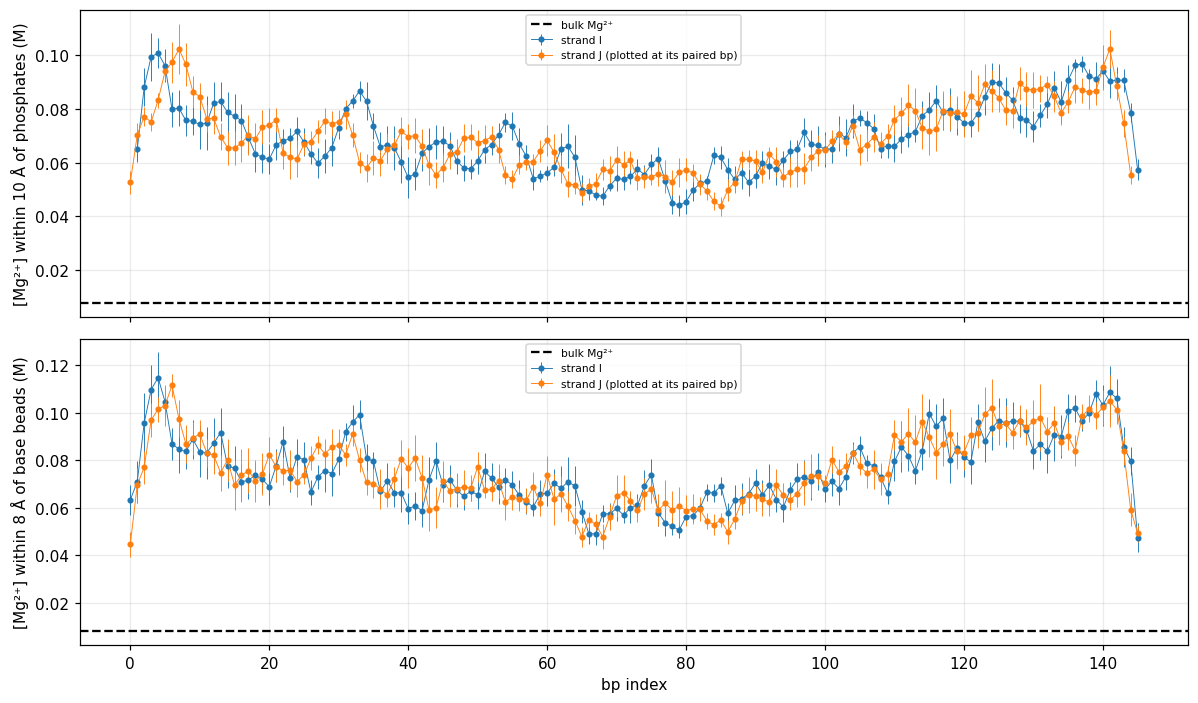

In [32]:
Lb = REF["L"]; mg = "Mg" if any("ploc_Mg" in RES[cond][r] for r in RES[cond]) else None
reps_m = [r for r in RES[cond] if mg and "ploc_Mg" in RES[cond][r] and len(prod(cond, r, "ploc_Mg")) > 0]
if not reps_m:
    print("no Mg data in the production window")
else:
    conv = lambda x, R: x * 1660.539 / (4 / 3 * np.pi * R ** 3)       # ions per sphere -> M
    ploc = np.array([pmean(cond, r, "ploc_Mg") for r in reps_m]); bloc = np.array([pmean(cond, r, "bloc_Mg") for r in reps_m])
    mp, ep = mean_sem(conv(ploc, R_LOC)); mb, eb = mean_sem(conv(bloc, R_BASE_LOC))
    bulk = np.nanmean([np.nanmean(prod(cond, r, "bulk_M_Mg")) for r in reps_m])
    fig, axs = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    for ax_, m_, e_, nm_, Rr in ((axs[0], mp, ep, "phosphates", R_LOC), (axs[1], mb, eb, "base beads", R_BASE_LOC)):
        ax_.errorbar(np.arange(Lb), m_[:Lb], e_[:Lb], fmt=".-", lw=.6, label="strand I")
        ax_.errorbar(Lb - 1 - np.arange(Lb), m_[Lb:], e_[Lb:], fmt=".-", lw=.6, label="strand J (plotted at its paired bp)")
        if SHOW_MN_COMPARISON:
            for s in REF["mn_sites"]: ax_.axvline(s["bp"], c="r", ls=":", lw=.8)
        ax_.axhline(bulk, c="k", ls="--", label="bulk Mg²⁺")
        ax_.set(ylabel=f"[Mg²⁺] within {Rr:.0f} Å of {nm_} (M)"); ax_.legend(fontsize=7)
    axs[1].set(xlabel="bp index"); plt.tight_layout()
    # model-intrinsic summary: how strongly is Mg2+ enriched next to the DNA relative to the bulk?
    print(f"bulk Mg²⁺ = {bulk*1000:.1f} mM")
    print(f"mean local [Mg²⁺] around phosphates (within {R_LOC:.0f} Å): {np.nanmean(mp)*1000:.0f} mM = {np.nanmean(mp)/bulk:.1f}x bulk")
    print(f"mean local [Mg²⁺] around base beads (within {R_BASE_LOC:.0f} Å): {np.nanmean(mb)*1000:.0f} mM = {np.nanmean(mb)/bulk:.1f}x bulk")
    print(f"spread along the DNA (std of the per-bp profile): phosphates {np.nanstd(mp)*1000:.0f} mM, base beads {np.nanstd(mb)*1000:.0f} mM  (includes statistical noise and the DNA ends; compare it with the error bars in the plot)")
    print("The CG DNA has no base atoms and no site-specific Mg²⁺ term: any enrichment here is electrostatic, uniform and non-specific by construction.")
    if SHOW_MN_COMPARISON:
        print("\nOPTIONAL comparison with the crystallographic Mn²⁺ sites (2CV5). Read the caveats in the note below before using it:")
        print("  Mn²⁺ is not Mg²⁺, the simulations contain no Mn²⁺, the CG DNA has no N7/O6, and most replicas are not in the crystal register.")
        print("  bp coordinating Mn²⁺ in 2CV5:", sorted({s['bp'] for s in REF['mn_sites']}), "| atoms:", sorted({s['atom'] for s in REF['mn_sites']}))
        base_of = np.empty(2 * Lb, dtype="<U1")
        for b_ in REF["dna"]:
            if b_["bead"] == "B": base_of[b_["strand"] * Lb + b_["nt"]] = b_["base"]
        site_idx = [s["strand"] * Lb + s["nt"] for s in REF["mn_sites"]]; G_idx = np.where(base_of == "G")[0]
        cb = conv(bloc, R_BASE_LOC).mean(0)
        print(f"  local [Mg²⁺] around base beads (M): Mn-coordinating nucleotides {np.nanmean(cb[site_idx]):.3f} | all guanines {np.nanmean(cb[G_idx]):.3f} | all bases {np.nanmean(cb):.3f} | bulk {bulk:.4f}")

**Experimental comparison — local Mg²⁺ around the DNA**

* What §9 measures is model-intrinsic: the local [Mg²⁺] next to phosphates and base beads relative to the bulk, and how it varies along the DNA. In this force field Mg²⁺ interacts with DNA only through electrostatics and excluded volume, and the CG DNA has no base atoms, so any enrichment is **uniform and non-specific by construction** — there is no mechanism for site-specific binding.
* The appropriate experimental counterpart is ion counting (total excess Mg²⁺/K⁺ per nucleosome; see the ion section), not site positions. Compare numbers only after checking that the salt conditions and the definition of "excess ions" match.
* **Mn²⁺ comparison (optional, off by default).** The 2CV5 crystal contains Mn²⁺ on guanine N7/O6. It is not a valid test here: the simulations contain no Mn²⁺ (Mn²⁺ binds base nitrogens differently from Mg²⁺), the CG DNA has no N7/O6 to coordinate, the crystal conditions (packing, 100 K) differ, and most replicas are not in the crystal register, so the same nucleotide index is not the same 3D environment. A null result would not mean "no specificity"; it would mean the comparison was not able to detect it. Set `SHOW_MN_COMPARISON = True` only for exploratory use.

## 10. Mg²⁺ scan summary (fill `mg_mM` in `CONDITIONS` and add one condition per concentration)

In [33]:
def summarize(cond):
    rows = {}
    for r in RES[cond]:
        h = prod(cond, r, "hand"); nrl = (h == 1).sum() + (h == -1).sum()
        d = dict(n_close=np.nanmean(prod(cond, r, "n_close")), n_wrap_c=np.nanmean(prod(cond, r, "n_wrap_c")), Q_native=np.nanmean(prod(cond, r, "Q")), Q_flip=np.nanmean(prod(cond, r, "Q_flip")), n_nat_bp=np.nanmean(prod(cond, r, "n_nat_bp")),
                 end_dist=np.nanmean(prod(cond, r, "end_dist")), wrap_angle=np.nanmean(prod(cond, r, "wrap_angle")),
                 frac_right=(h == 1).sum() / nrl if nrl else np.nan)
        for k in ION_RESNAMES:
            if f"gam_{k}" in RES[cond][r]:
                ip = int(np.argmin(abs(EDGES[1:] - R_PLATEAU)))
                g = prod(cond, r, f"gam_{k}")
                d[f"Gamma_{k}@{R_PLATEAU:.0f}"] = np.nanmean(g[:, ip]) if len(g) else np.nan
        rows[r] = d
    return pd.DataFrame(rows).T.infer_objects()

summary = {c: summarize(c) for c in RES}
SUM = pd.concat({c: pd.DataFrame({"mean": s.mean(), "sem": s.std(ddof=1) / np.sqrt(len(s))}).T for c, s in summary.items()})
print(SUM.round(3))
xs = [(CONDITIONS[c]["mg_mM"], c) for c in RES if "[" not in c and CONDITIONS[c]["mg_mM"] is not None]
if len(xs) > 1:
    xs.sort(); cols = ["Q_native", "Q_flip", "n_close", "end_dist", "frac_right"] + [c for c in summary[xs[0][1]].columns if c.startswith("Gamma_Mg")]
    fig, ax = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.4))
    for a, col in zip(np.atleast_1d(ax), cols):
        a.errorbar([x for x, _ in xs], [summary[c][col].mean() for _, c in xs],
                   [summary[c][col].std(ddof=1) / np.sqrt(len(summary[c])) for _, c in xs], fmt="o-"); a.set(xlabel="[MgCl2] (mM)", ylabel=col)
    plt.tight_layout()

                      n_close  n_wrap_c  Q_native  Q_flip  n_nat_bp  end_dist  wrap_angle  frac_right  Gamma_K@50  Gamma_Cl@50  Gamma_Mg@50
baseline        mean  117.902   136.452     0.008   0.009     0.702    95.014     396.065       0.364       3.974        4.167       13.085
                sem     1.091     0.784     0.003   0.005     0.250     3.026      70.259       0.178       0.457        0.643        0.181
baseline[R→L]   mean  118.995   136.545     0.010   0.010     0.872    91.869     561.815       0.914       3.888        3.385       13.004
                sem       NaN       NaN       NaN     NaN       NaN       NaN         NaN         NaN         NaN          NaN          NaN
baseline[RIGHT] mean  116.765   137.767     0.008   0.000     0.713    83.214     151.105       1.000       3.784        4.516       13.119
                sem     2.044     0.714     0.007   0.000     0.691     2.575       4.107       0.000       1.025        1.665        0.480
baseline[LEFT]  mean

**Experimental comparison — Mg²⁺ dependence**

* Ion counting (Gebala 2019): Mg²⁺ binding per nucleosome as a function of Mg²⁺ in a monovalent background → compare Γ_Mg(c) directly (same axes).
* Chromatin compaction/self-association vs. Mg²⁺ (e.g. Schwarz & Hansen 1994 *JBC* 269:16284; Allahverdi *et al.* 2011 *NAR* 39:1680; Korolev, Nordenskiöld and co-workers): arrays fold and nucleosome core particles aggregate at low-mM Mg²⁺. A mononucleosome simulation cannot reproduce inter-nucleosome compaction, but the *Mg²⁺-dependent screening of DNA–DNA/DNA–histone electrostatics* (Γ_Mg, entry/exit-DNA distance, end unwrapping) is the single-particle precursor — state it as such.
* Keep the monovalent background fixed across the scan and use ≥ 4–5 Mg²⁺ concentrations spanning 0–10 mM (the experimental transition region).

**Not included on purpose** (no direct experimental observable): Mg²⁺ bridges, bridge–wrapping correlations, Mg²⁺ residence times. Report them only as mechanistic predictions, clearly labelled as such.

## 11. Add your own analysis

In [34]:
# Template: copy, rename, re-run the "Run" cell (set FORCE_RECOMPUTE = True once so the cache is rebuilt).
@observable(every=1)
def obs_example(ctx, S):
    core_rg = np.sqrt(((ctx["core"] - ctx["core"].mean(0))**2).sum(1).mean())
    return dict(core_rg=core_rg)
# Then plot with:  pooled(cond, "core_rg")   /   prod(cond, rep, "core_rg")   /   rep_means(cond, "core_rg")
# ...and add an "Experimental comparison" markdown cell below it before it goes into the paper.